# Benchmarking summary

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

BENCHMARK_DIR = os.path.join(
    "..", "benchmarking", "const_split_bott_ooa_zigzag_1s14__relate_tsinfer_true_topology_singer"
)
CHECKPOINT = "const_split_bott_zigzag_1s14__seq256_knn7w_rank3"
SCORES_DIR = os.path.join(BENCHMARK_DIR, "scores")
# The two tables that read_scores writes from the tables of the folders of TOOLS: the rows of one value per data set, and the
# rows with an index, summed over replicates, with the windows of replicate 0.
SCALARS_FILE = os.path.join("benchmark_summary_tables", "summary_scalars.csv.gz")
POOLED_FILE = os.path.join("benchmark_summary_tables", "summary_pooled.csv.gz")
# True reads the tables of the folders of TOOLS again, after new tables arrive.
REREAD = True
# The folder of the tables of each tool: those of score_benchmark.py, then those of score_arggnn.py, in the order of
# the figures.
TOOLS = {
    "relate": os.path.join(SCORES_DIR, "relate"),
    "tsinfer": os.path.join(SCORES_DIR, "tsinfer"),
    "singer": os.path.join(SCORES_DIR, "singer"),
    "true_topology": os.path.join(SCORES_DIR, "true_topology"),
    "arggnn": os.path.join(BENCHMARK_DIR, CHECKPOINT, "scores"),
}
# Models in the order of the figures. A model without tables is left out.
MODEL_ORDER = ["const", "split", "bott", "ooa", "zigzag_1s14"]
# The sample sizes of the figures of one sample size.
SIZES_SHOWN = [10, 50, 100]
# The configuration of each method, with its label, and the references on the simulated topology.
METHODS = {
    "relate": "Relate",
    "tsinfer_tsdate": "tsinfer + tsdate",
    "singer_polegon": "SINGER + POLEGON",
    "arggnn_tsdate": "argGNN + tsdate",
    "arggnn_polegon": "argGNN + POLEGON",
}
REFERENCES = {
    "true_topology_tsdate": "simulated topology + tsdate",
    "true_topology_polegon": "simulated topology + POLEGON",
}
SHOWN = METHODS | REFERENCES
# Other checkpoints of argGNN, each scored by score_arggnn.py into a folder of its own: the folder of its tables and
# the suffix of its configurations. They are in the tables, not in the figures.
OTHER_CHECKPOINTS = {
    os.path.join(
        BENCHMARK_DIR, f"{CHECKPOINT}_finetuned_ooa_10_epochs_lr_2e-4", "scores"
    ): "_finetuned_ooa"
}
TABLE_ONLY = {
    "arggnn_tsdate_finetuned_ooa": "argGNN fine-tuned on ooa + tsdate",
    "arggnn_polegon_finetuned_ooa": "argGNN fine-tuned on ooa + POLEGON",
}
# The tool whose tables hold each configuration.
TOOL_OF = {
    "relate": "relate",
    "tsinfer_tsdate": "tsinfer",
    "singer_polegon": "singer",
    "true_topology_tsdate": "true_topology",
    "true_topology_polegon": "true_topology",
    "arggnn_tsdate": "arggnn",
    "arggnn_polegon": "arggnn",
}
# One Okabe-Ito color, line style, and marker per configuration, the same in every figure, the blues for argGNN.
COLOR_OF = dict(
    zip(
        SHOWN,
        ["#009E73", "#E69F00", "#CC79A7", "#0072B2", "#56B4E9", "#000000", "#D55E00"],
    )
)
LINE_OF = {
    configuration: "--" if configuration in REFERENCES else "-"
    for configuration in SHOWN
}
MARKER_OF = dict(zip(SHOWN, ["o", "s", "v", "D", "^", "X", "P"]))
# The color of the simulated values and of the nominal lines.
SIMULATION_COLOR = "#808080"
# The steps that each method needs, with its configuration: those of run_times.csv for the tools of
# score_benchmark.py, and those that score_arggnn.py times for argGNN, whose decode step is the decode of the
# tree at every SNP. Relate's include its 100 draws, which give its calibration.
RUN_TIME_STEPS = {
    "Relate": (
        "relate",
        [
            "relate_mode_all",
            "relate_estimate_population_size",
            "relate_sample_branch_lengths",
        ],
    ),
    "tsinfer + tsdate": ("tsinfer_tsdate", ["tsinfer", "preprocess_ts", "tsdate"]),
    "SINGER + POLEGON": (
        "singer_polegon",
        ["singer_chain", "singer_convert_and_trace", "polegon"],
    ),
    "argGNN + tsdate": (
        "arggnn_tsdate",
        ["predict", "decode", "assemble", "tsdate"],
    ),
    "argGNN + POLEGON": (
        "arggnn_polegon",
        ["predict", "decode", "assemble", "polegon"],
    ),
    "argGNN fine-tuned on ooa + tsdate": (
        "arggnn_tsdate_finetuned_ooa",
        ["predict", "decode", "assemble", "tsdate"],
    ),
    "argGNN fine-tuned on ooa + POLEGON": (
        "arggnn_polegon_finetuned_ooa",
        ["predict", "decode", "assemble", "polegon"],
    ),
    "simulated topology + tsdate": ("true_topology_tsdate", ["parsimony", "tsdate"]),
    "simulated topology + POLEGON": ("true_topology_polegon", ["parsimony", "polegon"]),
}
# argGNN's prediction time, from one run of time_predictions.py that predicted every data set again with each
# checkpoint, the ooa data sets with both checkpoints in the same job, so that all the times compare: the folder of
# the tables of each checkpoint, and the configurations that take its times in place of those of the argGNN tables.
PREDICTION_TIMES = {
    os.path.join(BENCHMARK_DIR, CHECKPOINT, "prediction_times"): [
        "arggnn_tsdate",
        "arggnn_polegon",
    ],
    os.path.join(BENCHMARK_DIR, f"{CHECKPOINT}_finetuned_ooa_10_epochs_lr_2e-4", "prediction_times"): [
        "arggnn_tsdate_finetuned_ooa",
        "arggnn_polegon_finetuned_ooa",
    ],
}
# The metrics ranked within each replicate, with the title of their figures and how a value becomes a score where
# lower is better: "value", "minus" (higher is better), "absolute" (0 is best), "coverage" (the distance to the
# coverage of a calibrated posterior, NOMINAL for the analytic intervals of tsdate and SAMPLE_EXPECTED for the
# intervals of 100 draws), or "minutes" (the run time of RANK_TIME_STEPS).
RANK_METRICS = {
    "RMSLE": ("RMSLE", "value"),
    "bias": ("absolute bias", "absolute"),
    "r_bar": (r"$\bar r$", "minus"),
    "rho_bar": (r"$\bar\rho$", "minus"),
    "J": ("Jeffreys divergence", "value"),
    "L2": ("coalescence-rate L2", "value"),
    "RMSLE_pi": (r"RMSLE of $\pi_w$", "value"),
    "bias_pi": (r"absolute bias of $\pi_w$", "absolute"),
    "RMSLE_D": (r"RMSLE of $D_w$", "value"),
    "bias_D": (r"absolute bias of $D_w$", "absolute"),
    "RMSLE_a": ("RMSLE of mutation ages", "value"),
    "bias_a": ("absolute bias of mutation ages", "absolute"),
    "rho_a": (r"Spearman $\rho$ of ages", "minus"),
    "coverage_50": ("distance of the 50% coverage to its target", "coverage"),
    "coverage_70": ("distance of the 70% coverage to its target", "coverage"),
    "coverage_90": ("distance of the 90% coverage to its target", "coverage"),
    "KL": ("KL divergence of ranks", "value"),
    "RF": ("RF", "value"),
    "KC": ("KC", "value"),
    "WT": ("wrong triplets", "value"),
    "minutes": ("minutes per data set", "minutes"),
}
# The models of the 2 x 2 figures, by row, and the configurations ranked there and on ooa, which adds the checkpoint
# fine-tuned on ooa. The references on the simulated topology are not ranked.
RANK_GRID = [["const", "split"], ["bott", "zigzag_1s14"]]
RANKED = list(METHODS)
RANKED_OOA = list(METHODS) + list(TABLE_ONLY)
# The configurations whose intervals come from 100 draws, those of Relate and of POLEGON. The others are tsdate's.
DRAWN = {
    configuration
    for configuration in RANKED_OOA
    if configuration == "relate" or "polegon" in configuration
}
# RF, KC, and WT rank each topology once: both datings of an argGNN topology have the same values, so the tsdate
# configuration stands for the topology, with the label of TOPOLOGY_LABEL.
TOPOLOGY_RANKED = {"RF", "KC", "WT"}
TOPOLOGY_SKIP = {
    "arggnn_polegon",
    "arggnn_polegon_finetuned_ooa",
}
TOPOLOGY_LABEL = {
    "arggnn_tsdate": "argGNN",
    "arggnn_tsdate_finetuned_ooa": "argGNN fine-tuned on ooa",
}
# The steps of the run time of each configuration, those of RUN_TIME_STEPS.
RANK_TIME_STEPS = {
    configuration: steps for configuration, steps in RUN_TIME_STEPS.values()
}
# Samples or draws behind each rank, so ranks run from 0 to 100.
POSTERIOR_SAMPLES = 100
# Levels of the central intervals of the coverage.
LEVELS = [0.5, 0.7, 0.9]
# The share of simulated values that the end of the last bin of the rates must leave older, as for L2.
RATE_TAIL = 0.01
# The metrics of each figure and table, with their labels. RMSLE, bias, and L2 are those of all pairs.
TMRCA_METRICS = {
    "RMSLE": "RMSLE",
    "bias": "bias",
    "r_bar": r"$\bar r$",
    "rho_bar": r"$\bar\rho$",
    "J": "Jeffreys divergence",
}
RATE_METRICS = {"L2": "coalescence-rate L2"}
WINDOW_METRICS = {
    "RMSLE_pi": r"RMSLE of $\pi_w$",
    "bias_pi": r"bias of $\pi_w$",
    "RMSLE_D": r"RMSLE of $D_w$",
    "bias_D": r"bias of $D_w$",
}
AGE_METRICS = {
    "RMSLE_a": "RMSLE of mutation ages",
    "bias_a": "bias of mutation ages",
    "rho_a": r"Spearman $\rho$ of ages",
}
CALIBRATION_METRICS = {
    "coverage_50": "50% coverage",
    "coverage_70": "70% coverage",
    "coverage_90": "90% coverage",
    "KL": "KL divergence of ranks",
}
TOPOLOGY_METRICS = {
    "RF": "RF",
    "KC": "KC",
    "WT": "wrong triplets",
    "mean_arity": "mean arity",
    "polytomies": "polytomies",
    "trees": "number of trees",
}
PAIR_CLASS_METRICS = {"RMSLE": "RMSLE", "bias": "bias", "L2": "coalescence-rate L2"}
# Values of a perfect metric or of a calibrated posterior, and the expected coverage with M samples or draws.
NOMINAL = {"bias": 0, "bias_pi": 0, "bias_D": 0, "bias_a": 0, "KL": 0} | {
    f"coverage_{round(100 * level)}": level for level in LEVELS
}
SAMPLE_EXPECTED = {
    f"coverage_{round(100 * level)}": (POSTERIOR_SAMPLES - 1)
    * level
    / (POSTERIOR_SAMPLES + 1)
    for level in LEVELS
}
pd.set_option("display.max_rows", 1000)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

In [2]:
def read_group(paths):
    """The tables of one tool, model, and sample size: the rows of one value per data set, the rows with an index
    summed over replicates with the number of replicates that have them, and the windows of replicate 0.
    """
    table_df = pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)
    table_df["pair_class"] = table_df["pair_class"].fillna("")
    has_index = table_df["index"].notna()
    scalars_df = table_df[~has_index].drop(columns=["index", "index_2"])
    # index_2 is set only for the 2D histograms, so -1 marks the rows without it.
    arrays_df = table_df[has_index].assign(index_2=table_df["index_2"].fillna(-1))
    keys = [
        "model",
        "size",
        "configuration",
        "quantity",
        "pair_class",
        "index",
        "index_2",
    ]
    pooled_df = arrays_df.groupby(keys)["value"].agg(["sum", "count"]).reset_index()
    windows_df = arrays_df[
        arrays_df["quantity"].isin(["pi_w", "D_w"]) & (arrays_df["replicate"] == 0)
    ]
    return scalars_df, pooled_df, windows_df


def read_scores():
    """Every table of the folders of TOOLS, as the rows of one value per data set and the rows with an index summed over
    replicates, each with the tool of its tables, from the two summary tables unless REREAD is True or they are
    missing. The windows of replicate 0 are kept as they are, in the quantity pi_w_replicate_0 or D_w_replicate_0.
    The tables of OTHER_CHECKPOINTS add their rows of one value per data set, with the suffix of the checkpoint.
    """
    if not REREAD and os.path.exists(SCALARS_FILE) and os.path.exists(POOLED_FILE):
        # NaN is written as nan, so that the empty pair class stays an empty string.
        scalars_df = pd.read_csv(SCALARS_FILE, keep_default_na=False, na_values=["nan"])
        pooled_df = pd.read_csv(POOLED_FILE, keep_default_na=False, na_values=["nan"])
        return scalars_df, pooled_df
    scalar_parts, pooled_parts = [], []
    for tool, folder in TOOLS.items():
        paths = sorted(glob.glob(os.path.join(folder, "*", "*_S*_*.csv.gz")))
        # The tables of one model and sample size, from the names {model}_S{size}_{replicate}.csv.gz.
        groups = {}
        for path in paths:
            model, rest = os.path.basename(path)[: -len(".csv.gz")].rsplit("_S", 1)
            groups.setdefault((model, int(rest.split("_")[0])), []).append(path)
        for (model, size), group in sorted(groups.items()):
            scalars_df, pooled_df, windows_df = read_group(group)
            scalar_parts.append(scalars_df.assign(tool=tool))
            windows_df = windows_df.assign(
                quantity=windows_df["quantity"] + "_replicate_0",
                sum=windows_df["value"],
                count=1,
            )
            pooled_parts.append(
                pd.concat([pooled_df, windows_df[pooled_df.columns]]).assign(tool=tool)
            )
        print(f"{tool}: {len(paths)} tables", flush=True)
    for folder, suffix in OTHER_CHECKPOINTS.items():
        paths = sorted(glob.glob(os.path.join(folder, "*", "*_S*_*.csv.gz")))
        groups = {}
        for path in paths:
            model, rest = os.path.basename(path)[: -len(".csv.gz")].rsplit("_S", 1)
            groups.setdefault((model, int(rest.split("_")[0])), []).append(path)
        for (model, size), group in sorted(groups.items()):
            # The simulation rows are those of the tools of TOOLS, so they are left out.
            scalars_df = read_group(group)[0]
            scalars_df = scalars_df[scalars_df["configuration"] != "simulation"]
            scalar_parts.append(
                scalars_df.assign(
                    configuration=scalars_df["configuration"] + suffix, tool=folder
                )
            )
        print(f"{folder}: {len(paths)} tables", flush=True)
    scalars_df = pd.concat(scalar_parts, ignore_index=True)
    pooled_df = pd.concat(pooled_parts, ignore_index=True)
    scalars_df.to_csv(SCALARS_FILE, index=False, na_rep="nan")
    pooled_df.to_csv(POOLED_FILE, index=False, na_rep="nan")
    return scalars_df, pooled_df


def read_prediction_seconds():
    """argGNN's prediction time of every data set, from the tables of time_predictions.py in the folders of
    PREDICTION_TIMES, as rows of scalars_df for the configurations of each folder."""
    parts = []
    for folder, configurations in PREDICTION_TIMES.items():
        paths = sorted(glob.glob(os.path.join(folder, "*", "*.csv")))
        columns = [
            "model",
            "size",
            "replicate",
            "wall_seconds_predict",
            "identical_to_kept",
        ]
        times_df = (
            pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)
            if paths
            else pd.DataFrame(columns=columns)
        )
        # A data set timed twice would count twice.
        if times_df.duplicated(["model", "size", "replicate"]).any():
            raise ValueError(
                f"{folder} holds more than one prediction time of a data set"
            )
        print(
            f"{folder}: the prediction time of {len(times_df)} data sets, "
            f"{int(times_df['identical_to_kept'].sum())} predictions identical to the kept ones",
            flush=True,
        )
        times_df = times_df[columns[:4]].rename(
            columns={"wall_seconds_predict": "value"}
        )
        parts += [
            times_df.assign(
                configuration=configuration,
                quantity="wall_seconds_predict",
                pair_class="",
                tool=folder,
            )
            for configuration in configurations
        ]
    return pd.concat(parts, ignore_index=True)


def time_edges():
    """The edges tau_0 to tau_31 of the time bins of the sheet, from the simulation rows, and edges that a log axis
    can show: bin 0 from tau_1 / r to tau_1 and bin 30 from tau_30 to r tau_30, with r the ratio of two inner
    edges."""
    rows_df = pooled_df[
        (pooled_df["configuration"] == "simulation") & (pooled_df["quantity"] == "tau")
    ]
    # The sum over replicates divided by their number gives tau_b, the same in every table.
    edges = (
        rows_df.groupby("index")["sum"].first()
        / rows_df.groupby("index")["count"].first()
    ).to_numpy()
    ratio = edges[2] / edges[1]
    return edges, np.concatenate([[edges[1] / ratio], edges[1:-1], [edges[-2] * ratio]])


def pooled(configuration, model, size, quantity, pair_class=""):
    """The values of one quantity with an index, summed over replicates, as a table of index, index_2, sum, and
    count, empty for a model and size without tables. The simulation rows come from the tool of SIMULATION_TOOL.
    """
    tool = (
        SIMULATION_TOOL.get((model, size))
        if configuration == "simulation"
        else TOOL_OF[configuration]
    )
    return POOLED_OF.get(
        (tool, configuration, model, size, quantity, pair_class), pooled_df.iloc[:0]
    )


def scalar_values(quantity):
    """The rows of one quantity of one value per data set, for every configuration, model, size, and replicate."""
    return SCALARS_OF.get(quantity, scalars_df.iloc[:0])


def metric_values(metric):
    """The values of one metric, one per configuration and replicate, those of all pairs for a metric with pair
    classes."""
    selected_df = scalar_values(metric)
    selected_df = selected_df[selected_df["configuration"].isin(SHOWN | TABLE_ONLY)]
    if (selected_df["pair_class"] == "all").any():
        selected_df = selected_df[selected_df["pair_class"] == "all"]
    return selected_df


def table_label(label):
    """A figure label as plain text for a table, with its Greek letters and bars as characters."""
    for latex, plain in (
        (r"$\bar r$", "r\u0304"),
        (r"$\bar\rho$", "\u03c1\u0304"),
        (r"$\rho$", "\u03c1"),
        (r"$\pi_w$", "\u03c0_w"),
        (r"$D_w$", "D_w"),
    ):
        label = label.replace(latex, plain)
    return label


def mean_sd(values):
    """Mean ± standard deviation of a series in plain notation, the mean alone for one value, or nothing."""
    values = values.dropna()
    if values.empty:
        return ""
    if len(values) == 1:
        return f"{values.iloc[0]:.3g}"
    return f"{values.mean():.3g} ± {values.std():.2g}"


def plain_number(value, position=None):
    """A tick label in plain notation, with thousands separators and without trailing zeros."""
    return f"{value:,.0f}" if value >= 1 else f"{value:g}"


def log_axis(axis, which, ticks=12, subs=(1.0,)):
    """Major ticks at powers of ten, or at their multiples subs, in plain numbers on a log axis."""
    target = axis.xaxis if which == "x" else axis.yaxis
    target.set_major_locator(LogLocator(base=10, subs=subs, numticks=ticks))
    target.set_major_formatter(FuncFormatter(plain_number))
    target.set_minor_formatter(NullFormatter())


def legend_below(fig, axes, columns=4):
    """One legend below the figure, with every labeled line of its panels once."""
    handles = {}
    for axis in np.ravel(axes):
        for handle, label in zip(*axis.get_legend_handles_labels()):
            handles.setdefault(label, handle)
    if handles:
        fig.legend(
            list(handles.values()),
            list(handles),
            loc="outside lower center",
            ncol=columns,
            frameon=False,
        )


def replicate_counts():
    """The number of replicates of each configuration per model, one column per sample size."""
    return (
        scalar_values("tree_sequences")
        .groupby(["configuration", "model", "size"])["replicate"]
        .nunique()
        .unstack("size")
    )


def plot_metrics(metrics):
    """Mean and standard deviation over replicates of each metric against the sample size, one row per metric and
    one column per model."""
    fig, axes = plt.subplots(
        len(metrics),
        len(MODELS),
        figsize=(3.3 * len(MODELS) + 0.4, 2.5 * len(metrics) + 1.0),
        squeeze=False,
        sharex=True,
        sharey="row",
        layout="constrained",
    )
    # Horizontal offsets of the configurations around each sample size, so that their error bars do not overlap.
    spread = 0.015 * (max(SIZES) - min(SIZES)) if len(SIZES) > 1 else 0.3
    offsets = dict(zip(SHOWN, np.linspace(-spread, spread, len(SHOWN))))
    for row, (metric, title) in enumerate(metrics.items()):
        values_df = metric_values(metric)
        for column, model in enumerate(MODELS):
            axis = axes[row, column]
            for configuration, label in SHOWN.items():
                selected_df = values_df[
                    (values_df["configuration"] == configuration)
                    & (values_df["model"] == model)
                ]
                statistics_df = (
                    selected_df.groupby("size")["value"]
                    .agg(["mean", "std"])
                    .reindex(SIZES)
                )
                # A configuration without this metric gets no line.
                if statistics_df["mean"].isna().all():
                    continue
                axis.errorbar(
                    np.array(SIZES) + offsets[configuration],
                    statistics_df["mean"],
                    yerr=statistics_df["std"],
                    color=COLOR_OF[configuration],
                    linestyle=LINE_OF[configuration],
                    marker=MARKER_OF[configuration],
                    markersize=3,
                    capsize=2,
                    linewidth=1,
                    label=label,
                )
            if metric in NOMINAL:
                axis.axhline(
                    NOMINAL[metric],
                    color=SIMULATION_COLOR,
                    linestyle=":",
                    linewidth=1,
                    label="perfect or nominal value",
                )
            if metric in SAMPLE_EXPECTED:
                axis.axhline(
                    SAMPLE_EXPECTED[metric],
                    color=SIMULATION_COLOR,
                    linestyle="-.",
                    linewidth=1,
                    label=f"expected with {POSTERIOR_SAMPLES} samples",
                )
            axis.set_xticks(SIZES)
            axis.ticklabel_format(axis="y", style="plain", useOffset=False)
            if row == 0:
                axis.set_title(model, fontsize=10)
            if column == 0:
                axis.set_ylabel(title)
            if row == len(metrics) - 1:
                axis.set_xlabel("haplotypes")
    legend_below(fig, axes)
    plt.show()


def metric_table(metrics):
    """Mean ± standard deviation over replicates of each metric, one row per metric, method, and model, and one
    column per sample size."""
    rows = []
    for metric, title in metrics.items():
        values_df = metric_values(metric)
        for (configuration, model, size), group_df in values_df.groupby(
            ["configuration", "model", "size"]
        ):
            rows.append(
                {
                    "metric": table_label(title),
                    "method": (SHOWN | TABLE_ONLY)[configuration],
                    "model": model,
                    "size": size,
                    "value": mean_sd(group_df["value"]),
                }
            )
    table_df = pd.DataFrame(rows).pivot(
        index=["metric", "method", "model"], columns="size", values="value"
    )
    # The rows in the order of the metrics, the methods, and the models.
    order = {
        title: rank
        for rank, title in enumerate(
            [table_label(title) for title in metrics.values()]
            + list((METHODS | TABLE_ONLY | REFERENCES).values())
            + MODELS
        )
    }
    return table_df.sort_index(key=lambda level: level.map(order)).fillna("")


def pair_class_table(metrics):
    """Mean ± standard deviation over replicates of each metric per pair class of the models with more than one
    population, one column per sample size."""
    rows = []
    for metric, title in metrics.items():
        selected_df = scalar_values(metric)
        selected_df = selected_df[
            selected_df["configuration"].isin(SHOWN | TABLE_ONLY)
            & selected_df["pair_class"].str.contains("_")
        ]
        for (configuration, model, pair_class, size), group_df in selected_df.groupby(
            ["configuration", "model", "pair_class", "size"]
        ):
            rows.append(
                {
                    "metric": title,
                    "method": (SHOWN | TABLE_ONLY)[configuration],
                    "model": model,
                    "pair class": pair_class.replace("_", " "),
                    "size": size,
                    "value": mean_sd(group_df["value"]),
                }
            )
    if not rows:
        return pd.DataFrame()
    table_df = pd.DataFrame(rows).pivot(
        index=["metric", "method", "model", "pair class"],
        columns="size",
        values="value",
    )
    order = {
        title: rank
        for rank, title in enumerate(
            list(metrics.values())
            + list((METHODS | TABLE_ONLY | REFERENCES).values())
            + MODELS
        )
    }
    return table_df.sort_index(
        key=lambda level: level.map(lambda value: order.get(value, value))
    ).fillna("")


def plot_distributions(size):
    """Distribution of the pairwise TMRCA of each configuration, filled, under the simulated one, pooled over
    replicates, one row per model and one column per configuration."""
    edges = PLOT_EDGES
    fig, axes = plt.subplots(
        len(MODELS),
        len(SHOWN),
        figsize=(2.9 * len(SHOWN) + 0.4, 2.2 * len(MODELS) + 1.0),
        squeeze=False,
        sharex=True,
        sharey="row",
        layout="constrained",
    )
    for row, model in enumerate(MODELS):
        simulated_df = pooled("simulation", model, size, "histogram_count")
        for column, (configuration, label) in enumerate(SHOWN.items()):
            axis = axes[row, column]
            inferred_df = pooled(configuration, model, size, "histogram_count")
            if inferred_df.empty:
                axis.set_visible(False)
                continue
            # The counts of each bin summed over replicates and divided by their total.
            axis.stairs(
                inferred_df["sum"] / inferred_df["sum"].sum(),
                edges,
                fill=True,
                alpha=0.5,
                color=COLOR_OF[configuration],
                label=label,
            )
            axis.stairs(
                simulated_df["sum"] / simulated_df["sum"].sum(),
                edges,
                color=SIMULATION_COLOR,
                linewidth=1.2,
                label="simulated",
            )
            axis.set_xscale("log")
            log_axis(axis, "x", ticks=6)
            axis.set_title(f"{model}, {label}", fontsize=8)
            if column == 0:
                axis.set_ylabel("fraction of pairs")
            if row == len(MODELS) - 1:
                axis.set_xlabel("pairwise TMRCA (generations)")
    fig.suptitle(f"{size} haplotypes", fontsize=10)
    legend_below(fig, axes, columns=6)
    plt.show()


def plot_histograms_2d(size, quantity, annotations):
    """2D histograms of inferred against simulated values, pooled over replicates, one row per model and one column
    per configuration, with the means over replicates of the metrics in annotations."""
    edges = PLOT_EDGES
    fig, axes = plt.subplots(
        len(MODELS),
        len(SHOWN),
        figsize=(2.9 * len(SHOWN) + 0.8, 2.6 * len(MODELS) + 0.6),
        squeeze=False,
        sharex=True,
        sharey=True,
        layout="constrained",
    )
    for row, model in enumerate(MODELS):
        for column, (configuration, label) in enumerate(SHOWN.items()):
            axis = axes[row, column]
            counts_df = pooled(configuration, model, size, quantity)
            if counts_df.empty:
                axis.set_visible(False)
                continue
            # The counts summed over replicates, with the simulated bin in rows and the inferred bin in columns.
            counts = np.zeros((len(edges) - 1, len(edges) - 1))
            counts[counts_df["index"].astype(int), counts_df["index_2"].astype(int)] = (
                counts_df["sum"]
            )
            mesh = axis.pcolormesh(
                edges,
                edges,
                np.where(counts > 0, counts, np.nan).T,
                norm=LogNorm(),
                cmap="viridis",
            )
            axis.plot(
                edges[[0, -1]],
                edges[[0, -1]],
                color="white",
                linestyle=":",
                linewidth=0.8,
            )
            axis.set_xscale("log")
            axis.set_yscale("log")
            log_axis(axis, "x", ticks=5)
            log_axis(axis, "y", ticks=5)
            # The means over replicates of the metrics of the panel.
            text = []
            for metric, metric_label in annotations.items():
                values_df = metric_values(metric)
                values = values_df.loc[
                    (values_df["configuration"] == configuration)
                    & (values_df["model"] == model)
                    & (values_df["size"] == size),
                    "value",
                ]
                text.append(f"{metric_label} {values.mean():.3f}")
            axis.text(
                0.03,
                0.97,
                "\n".join(text),
                transform=axis.transAxes,
                va="top",
                fontsize=7,
                bbox={
                    "facecolor": "white",
                    "alpha": 0.8,
                    "edgecolor": "none",
                    "pad": 1.5,
                },
            )
            axis.set_title(f"{model}, {label}", fontsize=8)
            if row == len(MODELS) - 1:
                axis.set_xlabel("simulated (generations)")
            if column == 0:
                axis.set_ylabel("inferred (generations)")
            fig.colorbar(mesh, ax=axis, shrink=0.8)
    fig.suptitle(f"{size} haplotypes", fontsize=10)
    plt.show()


def plot_errors_by_time(size):
    """RMSLE and bias of the pairwise TMRCA by simulated and by inferred time, from N_b and the two sums of each bin
    summed over replicates, one row per model. Empty bins are left out."""
    centers = np.sqrt(PLOT_EDGES[:-1] * PLOT_EDGES[1:])
    panels = [
        ("simulated", "RMSLE"),
        ("simulated", "bias"),
        ("inferred", "RMSLE"),
        ("inferred", "bias"),
    ]
    fig, axes = plt.subplots(
        len(MODELS),
        len(panels),
        figsize=(3.3 * len(panels) + 0.4, 2.3 * len(MODELS) + 1.0),
        squeeze=False,
        sharex=True,
        sharey="col",
        layout="constrained",
    )
    for row, model in enumerate(MODELS):
        for configuration, label in SHOWN.items():
            for column, (time, error) in enumerate(panels):
                count_df = pooled(configuration, model, size, f"N_b_by_{time}_time")
                if count_df.empty:
                    continue
                sums_df = pooled(
                    configuration,
                    model,
                    size,
                    f"sum_e{'2' if error == 'RMSLE' else ''}_b_by_{time}_time",
                )
                count = count_df.set_index("index")["sum"]
                total = sums_df.set_index("index")["sum"].reindex(count.index)
                with np.errstate(divide="ignore", invalid="ignore"):
                    values = (
                        np.sqrt(total / count) if error == "RMSLE" else total / count
                    )
                # Empty bins are left out.
                values = values.where(count > 0)
                axes[row, column].plot(
                    centers[count.index.astype(int)],
                    values,
                    color=COLOR_OF[configuration],
                    linestyle=LINE_OF[configuration],
                    marker=MARKER_OF[configuration],
                    markersize=2.5,
                    linewidth=1,
                    label=label,
                )
        for column, (time, error) in enumerate(panels):
            axis = axes[row, column]
            axis.set_xscale("log")
            log_axis(axis, "x", ticks=6)
            if error == "bias":
                axis.axhline(0, color=SIMULATION_COLOR, linestyle=":", linewidth=1)
            axis.set_title(f"{model}, {error} by {time} time", fontsize=8)
            if row == len(MODELS) - 1:
                axis.set_xlabel(f"{time} pairwise TMRCA (generations)")
    fig.suptitle(f"{size} haplotypes", fontsize=10)
    legend_below(fig, axes, columns=5)
    plt.show()


def pooled_rates(configuration, model, size, pair_class):
    """The coalescence rate lambda_b of bins 1 to b_max from the survival pooled over replicates, with half counts,
    and b_max from the pooled simulated survival without them.

    Every replicate has the same N, so the mean over replicates of S(tau_b) is the S of the pooled counts,
    S(tau_b) = sum_d c_d(tau_b) / sum_d N_d. With half counts, S_half(tau_b) = (sum_d c_d(tau_b) + 1/2) /
    (sum_d N_d + 1), and lambda_b = -(ln S_half(tau_{b+1}) - ln S_half(tau_b)) / (tau_{b+1} - tau_b). b_max is the
    last bin b with S(tau_{b+1}) >= RATE_TAIL for the simulated survival.
    """

    def survival(name):
        """The pooled counts c(tau_b), b = 0 to 30, and the pooled number of values N."""
        counts = pooled(name, model, size, "c_tau", pair_class)["sum"].to_numpy()
        tool = (
            SIMULATION_TOOL.get((model, size))
            if name == "simulation"
            else TOOL_OF[name]
        )
        number_df = scalar_values("N")
        number_df = number_df[
            (number_df["configuration"] == name)
            & (number_df["model"] == model)
            & (number_df["size"] == size)
            & (number_df["pair_class"] == pair_class)
            & (number_df["tool"] == tool)
        ]
        return counts, number_df["value"].sum()

    simulated_counts, simulated_number = survival("simulation")
    if simulated_counts.size == 0:
        return None
    simulated_survival = simulated_counts / simulated_number
    # The last bin b whose end tau_{b+1} leaves at least RATE_TAIL of the simulated values older.
    b_max = int(np.nonzero(simulated_survival[1:] >= RATE_TAIL)[0].max())
    counts, number = survival(configuration)
    if counts.size == 0:
        return None
    half = (counts + 0.5) / (number + 1)
    rates = -(np.log(half[1:]) - np.log(half[:-1])) / np.diff(TAU[:-1])
    return np.arange(1, b_max + 1), rates[1 : b_max + 1]


def rate_panel(axis, model, size, pair_class, between):
    """N_e = 1 / (2 lambda_b), or lambda_b between populations, of the simulation and of each configuration in one
    panel, for bins 1 to b_max."""
    edges = PLOT_EDGES
    for name, label in ({"simulation": "simulated"} | SHOWN).items():
        result = pooled_rates(name, model, size, pair_class)
        if result is None:
            continue
        bins, rates = result
        with np.errstate(divide="ignore"):
            values = rates if between else 1 / (2 * rates)
        # A bin without coalescences has no value on a log axis.
        values = np.where(np.isfinite(values) & (values > 0), values, np.nan)
        # No baseline, so the steps do not drop to the edge of the log axis at both ends.
        axis.stairs(
            values,
            edges[bins[0] : bins[-1] + 2],
            baseline=None,
            color=SIMULATION_COLOR if name == "simulation" else COLOR_OF[name],
            linestyle="-" if name == "simulation" else LINE_OF[name],
            linewidth=2.0 if name == "simulation" else 1.0,
            label=label,
        )
    axis.set_xscale("log")
    axis.set_yscale("log")
    log_axis(axis, "x", ticks=6)
    log_axis(axis, "y", ticks=6, subs=(1.0, 2.0, 5.0))
    axis.set_ylabel(r"$\lambda_b$" if between else r"$N_{e,b}$")


def plot_coalescence_rates():
    """N_e of all pairs in each bin from the pooled survival, one row per sample size of SIZES_SHOWN and one column
    per model."""
    fig, axes = plt.subplots(
        len(SIZES_SHOWN),
        len(MODELS),
        figsize=(3.3 * len(MODELS) + 0.4, 2.7 * len(SIZES_SHOWN) + 1.0),
        squeeze=False,
        sharex=True,
        layout="constrained",
    )
    for row, size in enumerate(SIZES_SHOWN):
        for column, model in enumerate(MODELS):
            axis = axes[row, column]
            rate_panel(axis, model, size, "all", False)
            axis.set_title(f"{model}, {size} haplotypes", fontsize=9)
            if row == len(SIZES_SHOWN) - 1:
                axis.set_xlabel("generations")
    legend_below(fig, axes, columns=6)
    plt.show()


def plot_pair_class_rates(model, size):
    """N_e within each population in the first row and lambda_b between two in the second, from the pooled
    survival."""
    classes = sorted(
        set(
            pooled_df.loc[
                (pooled_df["model"] == model) & (pooled_df["quantity"] == "c_tau"),
                "pair_class",
            ]
        )
        - {"all"}
    )
    within = [pair_class for pair_class in classes if pair_class.startswith("within_")]
    between = [
        pair_class for pair_class in classes if pair_class.startswith("between_")
    ]
    columns = max(len(within), len(between))
    fig, axes = plt.subplots(
        2,
        columns,
        figsize=(3.3 * columns + 0.4, 6.4),
        squeeze=False,
        sharex=True,
        layout="constrained",
    )
    for row, names in enumerate([within, between]):
        for column in range(columns):
            axis = axes[row, column]
            if column >= len(names):
                axis.set_visible(False)
                continue
            rate_panel(axis, model, size, names[column], row == 1)
            axis.set_title(
                f"{model}, {size} haplotypes, {names[column].replace('_', ' ')}",
                fontsize=8,
            )
            if row == 1:
                axis.set_xlabel("generations")
    legend_below(fig, axes, columns=6)
    plt.show()


def plot_diversity_along_genome(size, replicate_quantity="pi_w_replicate_0"):
    """pi_w in 10 kb windows along the genome of replicate 0, simulated and inferred, one row per model."""
    fig, axes = plt.subplots(
        len(MODELS),
        1,
        figsize=(13, 2.0 * len(MODELS) + 1.0),
        squeeze=False,
        sharex=True,
        layout="constrained",
    )
    for row, model in enumerate(MODELS):
        axis = axes[row, 0]
        for name, label in ({"simulation": "simulated"} | SHOWN).items():
            windows_df = pooled(name, model, size, replicate_quantity)
            if windows_df.empty:
                continue
            # Window w covers [10^4 (w - 1), 10^4 w), so its middle is at 10^4 (w - 1/2).
            axis.plot(
                (windows_df["index"] - 0.5) * 1e4 / 1e6,
                windows_df["sum"],
                color=SIMULATION_COLOR if name == "simulation" else COLOR_OF[name],
                linestyle="-" if name == "simulation" else LINE_OF[name],
                linewidth=2.0 if name == "simulation" else 0.8,
                label=label,
            )
        axis.set_yscale("log")
        axis.set_ylabel(r"$\pi_w$")
        axis.set_title(f"{model}, {size} haplotypes, replicate 0", fontsize=9)
    axes[-1, 0].set_xlabel("position (Mb)")
    legend_below(fig, axes, columns=6)
    plt.show()


def plot_ranks():
    """Rank fractions times M + 1, means over replicates, one row per sample size of SIZES_SHOWN and one column per
    model. A calibrated posterior gives 1 at every rank."""
    fig, axes = plt.subplots(
        len(SIZES_SHOWN),
        len(MODELS),
        figsize=(3.3 * len(MODELS) + 0.4, 2.5 * len(SIZES_SHOWN) + 1.0),
        squeeze=False,
        sharex=True,
        sharey=True,
        layout="constrained",
    )
    for row, size in enumerate(SIZES_SHOWN):
        for column, model in enumerate(MODELS):
            axis = axes[row, column]
            for configuration, label in SHOWN.items():
                fractions_df = pooled(configuration, model, size, "f_r")
                if fractions_df.empty:
                    continue
                # f_r averaged over replicates, which equals the pooled fractions.
                axis.plot(
                    fractions_df["index"],
                    fractions_df["sum"]
                    / fractions_df["count"]
                    * (POSTERIOR_SAMPLES + 1),
                    color=COLOR_OF[configuration],
                    linestyle=LINE_OF[configuration],
                    linewidth=1,
                    label=label,
                )
            axis.axhline(
                1,
                color=SIMULATION_COLOR,
                linestyle=":",
                linewidth=1,
                label="calibrated",
            )
            axis.set_yscale("log")
            axis.set_title(f"{model}, {size} haplotypes", fontsize=9)
            if row == len(SIZES_SHOWN) - 1:
                axis.set_xlabel("rank r")
            if column == 0:
                axis.set_ylabel(r"$(M + 1) f_r$")
    legend_below(fig, axes, columns=6)
    plt.show()


def plot_coverage():
    """Coverage of the central intervals against their level, means over replicates, one row per sample size of
    SIZES_SHOWN and one column per model."""
    fig, axes = plt.subplots(
        len(SIZES_SHOWN),
        len(MODELS),
        figsize=(3.3 * len(MODELS) + 0.4, 3.0 * len(SIZES_SHOWN) + 1.0),
        squeeze=False,
        sharex=True,
        sharey=True,
        layout="constrained",
    )
    names = [f"coverage_{round(100 * level)}" for level in LEVELS]
    coverage_df = pd.concat([scalar_values(name) for name in names])
    for row, size in enumerate(SIZES_SHOWN):
        for column, model in enumerate(MODELS):
            axis = axes[row, column]
            for configuration, label in SHOWN.items():
                selected_df = coverage_df[
                    (coverage_df["configuration"] == configuration)
                    & (coverage_df["model"] == model)
                    & (coverage_df["size"] == size)
                ]
                means = selected_df.groupby("quantity")["value"].mean().reindex(names)
                if means.isna().all():
                    continue
                axis.plot(
                    LEVELS,
                    means.to_numpy(),
                    color=COLOR_OF[configuration],
                    linestyle=LINE_OF[configuration],
                    marker=MARKER_OF[configuration],
                    markersize=4,
                    linewidth=1,
                    label=label,
                )
            axis.plot(
                [0, 1],
                [0, 1],
                color=SIMULATION_COLOR,
                linestyle=":",
                linewidth=1,
                label="nominal level",
            )
            axis.plot(
                [0, 1],
                [0, (POSTERIOR_SAMPLES - 1) / (POSTERIOR_SAMPLES + 1)],
                color=SIMULATION_COLOR,
                linestyle="-.",
                linewidth=1,
                label=f"expected with {POSTERIOR_SAMPLES} samples",
            )
            axis.set_xlim(0.4, 1.0)
            axis.set_ylim(0.0, 1.0)
            axis.set_title(f"{model}, {size} haplotypes", fontsize=9)
            if row == len(SIZES_SHOWN) - 1:
                axis.set_xlabel(r"level $\gamma$")
            if column == 0:
                axis.set_ylabel("coverage")
    legend_below(fig, axes, columns=6)
    plt.show()


def run_time_table():
    """Minutes per data set of the steps of each method, mean ± standard deviation over the replicates with a time for
    every step, one row per method and model and one column per sample size."""
    rows = []
    for method, (configuration, steps) in RUN_TIME_STEPS.items():
        selected_df = pd.concat(
            [scalar_values(f"wall_seconds_{step}") for step in steps]
        )
        selected_df = selected_df[selected_df["configuration"] == configuration]
        # The minutes of one data set, the sum of its steps, for the data sets with a time for every step.
        grouped = selected_df.groupby(["model", "size", "replicate"])
        complete = grouped["quantity"].nunique() == len(steps)
        minutes_df = grouped["value"].sum()[complete] / 60
        if not complete.all():
            print(
                f"{method}: {(~complete).sum()} data sets without a time for every step are left out",
                flush=True,
            )
        for (model, size), values in minutes_df.groupby(["model", "size"]):
            rows.append(
                {
                    "method": method,
                    "model": model,
                    "size": size,
                    "value": mean_sd(values),
                }
            )
    table_df = pd.DataFrame(rows).pivot(
        index=["method", "model"], columns="size", values="value"
    )
    order = {name: rank for rank, name in enumerate(list(RUN_TIME_STEPS) + MODELS)}
    return table_df.sort_index(key=lambda level: level.map(order)).fillna("")


def run_time_steps_table():
    """Minutes per data set of each step of each method, mean ± standard deviation over the replicates with a time for
    the step, one row per method, step, and model and one column per sample size."""
    blocks = []
    for method, (configuration, steps) in RUN_TIME_STEPS.items():
        rows = []
        for step in steps:
            selected_df = scalar_values(f"wall_seconds_{step}")
            selected_df = selected_df[selected_df["configuration"] == configuration]
            for (model, size), values in selected_df.groupby(["model", "size"])[
                "value"
            ]:
                rows.append(
                    {
                        "method": method,
                        "step": step,
                        "model": model,
                        "size": size,
                        "value": mean_sd(values / 60),
                    }
                )
        if not rows:
            continue
        block_df = pd.DataFrame(rows).pivot(
            index=["method", "step", "model"], columns="size", values="value"
        )
        # The steps in their order of RUN_TIME_STEPS, then the models in the order of the figures.
        order = {name: rank for rank, name in enumerate([method] + steps + MODELS)}
        blocks.append(block_df.sort_index(key=lambda level: level.map(order)))
    return pd.concat(blocks).fillna("")


def replicate_scores(metric, configurations):
    """The score of each configuration, lower is better, one row per model, size, and replicate with a score for every
    configuration, and one column per configuration."""
    kind = RANK_METRICS[metric][1]
    if kind == "minutes":
        columns = []
        for configuration in configurations:
            steps = RANK_TIME_STEPS[configuration]
            selected_df = pd.concat(
                [scalar_values(f"wall_seconds_{step}") for step in steps]
            )
            grouped = selected_df[
                selected_df["configuration"] == configuration
            ].groupby(["model", "size", "replicate"])
            # The minutes of the data sets with a time for every step.
            complete = grouped["quantity"].nunique() == len(steps)
            columns.append(
                (grouped["value"].sum()[complete] / 60).rename(configuration)
            )
        scores_df = pd.concat(columns, axis=1)
    else:
        values_df = metric_values(metric)
        values_df = values_df[values_df["configuration"].isin(configurations)]
        scores_df = values_df.pivot(
            index=["model", "size", "replicate"],
            columns="configuration",
            values="value",
        )
        scores_df = scores_df.reindex(columns=configurations)
        if kind == "minus":
            scores_df = -scores_df
        elif kind == "absolute":
            scores_df = scores_df.abs()
        elif kind == "coverage":
            targets = pd.Series(
                {
                    configuration: (
                        SAMPLE_EXPECTED if configuration in DRAWN else NOMINAL
                    )[metric]
                    for configuration in configurations
                }
            )
            scores_df = (scores_df - targets).abs()
    # Only the replicates with a score for every configuration are ranked.
    return scores_df.reindex(columns=configurations).dropna()


def rank_summary(metric, configurations):
    """Mean and standard deviation over replicates of the rank of each configuration within its replicate, with the
    number of replicates, per model and size. Within a replicate, R_i = 1 + sum over j != i of 1[s_j < s_i] +
    (1/2) sum over j != i of 1[s_j = s_i] for the score s_i of configuration i, so tied configurations share the mean
    of the ranks they hold, and the ranks of every replicate sum to k (k + 1) / 2."""
    ranks_df = replicate_scores(metric, configurations).rank(axis=1, method="average")
    grouped = ranks_df.groupby(["model", "size"])
    return grouped.mean(), grouped.std(), grouped.size()


def rank_heatmap(axis, mean_df, sd_df, model, configurations, labels, k):
    """One heatmap of mean ranks, one row per configuration and one column per sample size, each cell with the mean
    and the standard deviation of the rank."""
    mean = mean_df.loc[model].reindex(index=SIZES, columns=configurations).T
    sd = sd_df.loc[model].reindex(index=SIZES, columns=configurations).T
    image = axis.imshow(
        mean.to_numpy(dtype=float), cmap="cividis_r", vmin=1, vmax=k, aspect="auto"
    )
    for row, configuration in enumerate(configurations):
        for column, size in enumerate(SIZES):
            value = mean.loc[configuration, size]
            if np.isfinite(value):
                # Dark text on the light cells of the low ranks, light text on the dark cells of the high ranks.
                color = "white" if (value - 1) / max(k - 1, 1) > 0.55 else "black"
                axis.text(
                    column,
                    row,
                    f"{value:.1f}\n±{sd.loc[configuration, size]:.1f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color=color,
                )
    axis.set_xticks(range(len(SIZES)), SIZES)
    axis.set_yticks(
        range(len(configurations)),
        [labels[configuration] for configuration in configurations],
    )
    axis.set_title(model, fontsize=10)
    return image


def plot_rank_heatmaps(metric):
    """The mean rank of each method within its replicates for one metric: a 2 x 2 figure of const, split, bott, and
    zigzag_1s14, then a figure of ooa with the checkpoint fine-tuned on ooa."""
    title = RANK_METRICS[metric][0]
    for grid, configurations in ((RANK_GRID, RANKED), ([["ooa"]], RANKED_OOA)):
        if metric in TOPOLOGY_RANKED:
            configurations = [
                configuration
                for configuration in configurations
                if configuration not in TOPOLOGY_SKIP
            ]
        labels = {
            configuration: (
                TOPOLOGY_LABEL.get(configuration) if metric in TOPOLOGY_RANKED else None
            )
            or (METHODS | TABLE_ONLY)[configuration]
            for configuration in configurations
        }
        mean_df, sd_df, counts = rank_summary(metric, configurations)
        models = set(mean_df.index.get_level_values("model")) if len(mean_df) else set()
        if not models & {model for row in grid for model in row}:
            print(
                f"{title}: no replicate with a score for every configuration of {', '.join(grid[0])}",
                flush=True,
            )
            continue
        k = len(configurations)
        fig, axes = plt.subplots(
            len(grid),
            len(grid[0]),
            squeeze=False,
            layout="constrained",
            figsize=(7.5 * len(grid[0]), (0.42 * k + 1.0) * len(grid) + 0.6),
        )
        for row, models_of_row in enumerate(grid):
            for column, model in enumerate(models_of_row):
                axis = axes[row, column]
                if model not in models:
                    axis.set_axis_off()
                    continue
                image = rank_heatmap(
                    axis, mean_df, sd_df, model, configurations, labels, k
                )
                if row == len(grid) - 1:
                    axis.set_xlabel("haplotypes")
        fig.colorbar(image, ax=axes, label="mean rank (1 = best)", shrink=0.9)
        fig.suptitle(
            f"{title}: rank within each replicate, mean ± standard deviation over {counts.min()} to "
            f"{counts.max()} replicates per cell",
            fontsize=11,
        )
        plt.show()

In [3]:
scalars_df, pooled_df = read_scores()
MODELS = [model for model in MODEL_ORDER if model in set(scalars_df["model"])]
SIZES = sorted(set(scalars_df["size"]))
SIZES_SHOWN = [size for size in SIZES_SHOWN if size in SIZES] or SIZES[-1:]
# Only the configurations with tables get a line, a column, or a row.
SHOWN = {
    configuration: label
    for configuration, label in SHOWN.items()
    if configuration in set(scalars_df["configuration"])
}
# The first tool of TOOLS with tables of each model and size, whose simulation rows are the simulated ARG of the
# figures, so that the simulated values of a figure come from one set of replicates.
SIMULATION_TOOL = {
    key: next(tool for tool in TOOLS if tool in tools)
    for key, tools in scalars_df.groupby(["model", "size"])["tool"].agg(set).items()
}
# argGNN's prediction time, from the run of time_predictions.py, in place of the times in the argGNN tables.
predict_df = read_prediction_seconds()
replaced = (scalars_df["quantity"] == "wall_seconds_predict") & scalars_df[
    "configuration"
].isin(
    [
        configuration
        for configurations in PREDICTION_TIMES.values()
        for configuration in configurations
    ]
)
scalars_df = pd.concat([scalars_df[~replaced], predict_df], ignore_index=True)
# The rows of each quantity, and the pooled rows of each tool, configuration, model, size, quantity, and pair class.
SCALARS_OF = dict(tuple(scalars_df.groupby("quantity")))
POOLED_OF = {
    key: group_df.sort_values(["index", "index_2"])
    for key, group_df in pooled_df.groupby(
        ["tool", "configuration", "model", "size", "quantity", "pair_class"]
    )
}
TAU, PLOT_EDGES = time_edges()
# The number of replicates of each configuration per model and sample size.
replicate_counts()

relate: 5000 tables


tsinfer: 5000 tables


singer: 5000 tables


true_topology: 5000 tables


arggnn: 5000 tables


../benchmarking/const_split_bott_ooa_zigzag_1s14__relate_tsinfer_true_topology_singer/const_split_bott_zigzag_1s14__seq256_knn7w_rank3_finetuned_ooa_10_epochs_lr_2e-4/scores: 1000 tables


../benchmarking/const_split_bott_ooa_zigzag_1s14__relate_tsinfer_true_topology_singer/const_split_bott_zigzag_1s14__seq256_knn7w_rank3/prediction_times: the prediction time of 5000 data sets, 5000 predictions identical to the kept ones


../benchmarking/const_split_bott_ooa_zigzag_1s14__relate_tsinfer_true_topology_singer/const_split_bott_zigzag_1s14__seq256_knn7w_rank3_finetuned_ooa_10_epochs_lr_2e-4/prediction_times: the prediction time of 1000 data sets, 1000 predictions identical to the kept ones


size                                      10   20   30   40   50   60   70   80   90   100
configuration                model                                                        
arggnn_polegon               bott         100  100  100  100  100  100  100  100  100  100
                             const        100  100  100  100  100  100  100  100  100  100
                             ooa          100  100  100  100  100  100  100  100  100  100
                             split        100  100  100  100  100  100  100  100  100  100
                             zigzag_1s14  100  100  100  100  100  100  100  100  100  100
arggnn_polegon_finetuned_ooa ooa          100  100  100  100  100  100  100  100  100  100
arggnn_tsdate                bott         100  100  100  100  100  100  100  100  100  100
                             const        100  100  100  100  100  100  100  100  100  100
                             ooa          100  100  100  100  100  100  100  100  100  100
                             split        100  100  100  100  100  100  100  100  100  100
                             zigzag_1s14  100  100  100  100  100  100  100  100  100  100
arggnn_tsdate_finetuned_ooa  ooa          100  100  100  100  100  100  100  100  100  100
relate                       bott         100  100  100  100  100  100  100  100  100  100
                             const        100  100  100  100  100  100  100  100  100  100
                             ooa          100  100  100  100  100  100  100  100  100  100
                             split        100  100  100  100  100  100  100  100  100  100
                             zigzag_1s14  100  100  100  100  100  100  100  100  100  100
singer_polegon               bott         100  100  100  100  100  100  100  100  100  100
                             const        100  100  100  100  100  100  100  100  100  100
                             ooa          100  100  100  100  100  100  100  100  100  100
                             split        100  100  100  100  100  100  100  100  100  100
                             zigzag_1s14  100  100  100  100  100  100  100  100  100  100
true_topology_polegon        bott         100  100  100  100  100  100  100  100  100  100
                             const        100  100  100  100  100  100  100  100  100  100
                             ooa          100  100  100  100  100  100  100  100  100  100
                             split        100  100  100  100  100  100  100  100  100  100
                             zigzag_1s14  100  100  100  100  100  100  100  100  100  100
true_topology_tsdate         bott         100  100  100  100  100  100  100  100  100  100
                             const        100  100  100  100  100  100  100  100  100  100
                             ooa          100  100  100  100  100  100  100  100  100  100
                             split        100  100  100  100  100  100  100  100  100  100
                             zigzag_1s14  100  100  100  100  100  100  100  100  100  100
tsinfer_tsdate               bott         100  100  100  100  100  100  100  100  100  100
                             const        100  100  100  100  100  100  100  100  100  100
                             ooa          100  100  100  100  100  100  100  100  100  100
                             split        100  100  100  100  100  100  100  100  100  100
                             zigzag_1s14  100  100  100  100  100  100  100  100  100  100

## Pairwise TMRCA

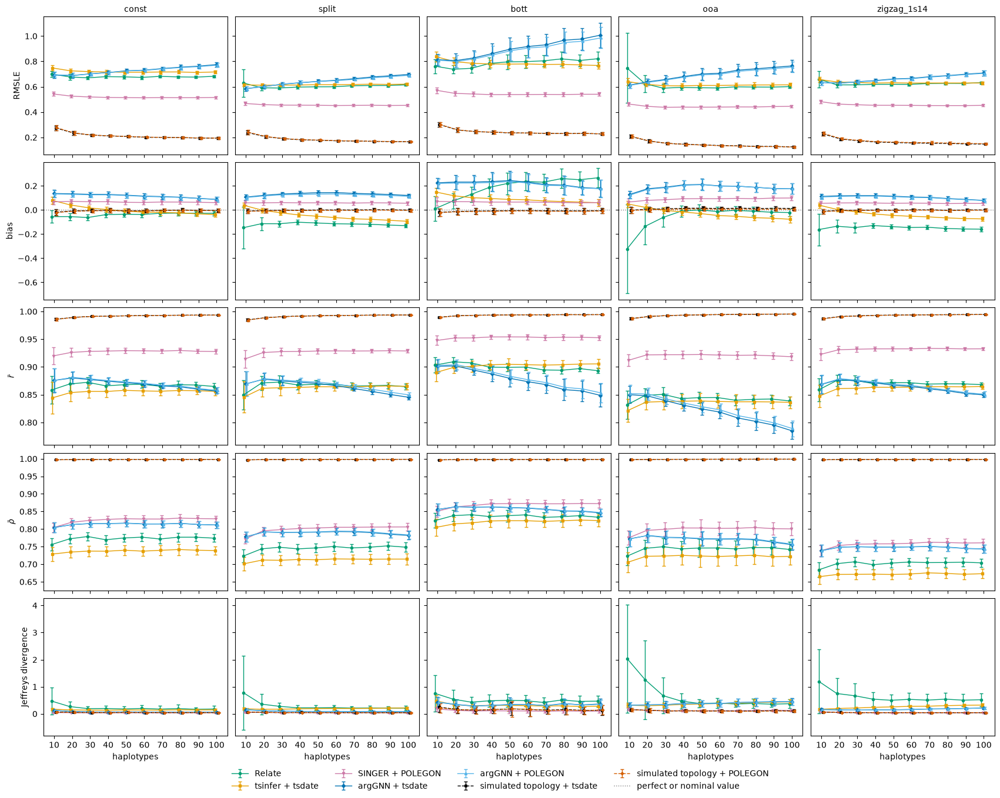

In [4]:
# Pairwise TMRCA metrics against the sample size, one row per metric and one column per model.
plot_metrics(TMRCA_METRICS)

In [5]:
# Mean ± standard deviation over replicates of the pairwise TMRCA metrics.
metric_table(TMRCA_METRICS)

size                                                                             10                20                30                 40                 50                60                 70                 80                90   \
metric              method                             model                                                                                                                                                                               
RMSLE               Relate                             const           0.701 ± 0.022     0.678 ± 0.024      0.67 ± 0.012       0.68 ± 0.011      0.678 ± 0.014     0.674 ± 0.013      0.682 ± 0.011       0.678 ± 0.01    0.676 ± 0.0099   
                                                       split             0.63 ± 0.11     0.592 ± 0.022      0.59 ± 0.012      0.597 ± 0.012       0.599 ± 0.01      0.6 ± 0.0089      0.608 ± 0.009      0.61 ± 0.0096    0.609 ± 0.0094   
                                                       bott            0.762 ± 0.056     0.738 ± 0.032     0.745 ± 0.035      0.784 ± 0.044      0.796 ± 0.058     0.798 ± 0.052      0.804 ± 0.046       0.82 ± 0.057     0.807 ± 0.047   
                                                       ooa              0.747 ± 0.28     0.624 ± 0.068      0.589 ± 0.03      0.595 ± 0.019      0.592 ± 0.017      0.59 ± 0.015      0.599 ± 0.015      0.598 ± 0.015     0.597 ± 0.013   
                                                       zigzag_1s14      0.66 ± 0.065     0.615 ± 0.022     0.614 ± 0.018     0.619 ± 0.0091     0.619 ± 0.0095    0.618 ± 0.0091     0.625 ± 0.0091     0.626 ± 0.0095     0.626 ± 0.009   
                    tsinfer + tsdate                   const            0.748 ± 0.02     0.725 ± 0.017     0.719 ± 0.014      0.716 ± 0.015      0.714 ± 0.014     0.714 ± 0.014      0.716 ± 0.014      0.717 ± 0.014     0.712 ± 0.013   
                                                       split           0.615 ± 0.015     0.612 ± 0.012     0.613 ± 0.012      0.613 ± 0.011      0.616 ± 0.011     0.616 ± 0.011      0.618 ± 0.011       0.62 ± 0.012     0.618 ± 0.011   
                                                       bott            0.837 ± 0.041     0.799 ± 0.032      0.785 ± 0.03       0.779 ± 0.03      0.779 ± 0.032      0.78 ± 0.028      0.776 ± 0.026      0.777 ± 0.027     0.772 ± 0.025   
                                                       ooa              0.64 ± 0.026     0.619 ± 0.019     0.608 ± 0.021       0.607 ± 0.02        0.61 ± 0.02      0.61 ± 0.017      0.612 ± 0.019      0.614 ± 0.019     0.614 ± 0.018   
                                                       zigzag_1s14      0.657 ± 0.02     0.637 ± 0.016     0.634 ± 0.013      0.629 ± 0.012      0.631 ± 0.013     0.629 ± 0.011      0.629 ± 0.011      0.629 ± 0.012     0.629 ± 0.011   
                    SINGER + POLEGON                   const           0.543 ± 0.016     0.526 ± 0.011      0.519 ± 0.01     0.516 ± 0.0088       0.514 ± 0.01    0.513 ± 0.0097     0.514 ± 0.0087     0.513 ± 0.0083     0.514 ± 0.008   
                                                       split           0.468 ± 0.013    0.459 ± 0.0085    0.455 ± 0.0078     0.454 ± 0.0093     0.454 ± 0.0085     0.452 ± 0.008     0.453 ± 0.0068     0.454 ± 0.0076    0.452 ± 0.0073   
                                                       bott            0.571 ± 0.024     0.547 ± 0.017     0.543 ± 0.017      0.538 ± 0.014      0.538 ± 0.016     0.538 ± 0.016      0.539 ± 0.015      0.538 ± 0.016      0.54 ± 0.013   
                                                       ooa             0.463 ± 0.015     0.445 ± 0.014     0.437 ± 0.012      0.439 ± 0.012      0.438 ± 0.011     0.439 ± 0.012      0.441 ± 0.012      0.44 ± 0.0099    0.443 ± 0.0094   
                                                       zigzag_1s14     0.482 ± 0.012      0.463 ± 0.01    0.458 ± 0.0096     0.453 ± 0.0068      0.453 ± 0.008    0.453 ± 0.0063     0.451 ± 0.0075     0.451 ± 0.0068    0.451 

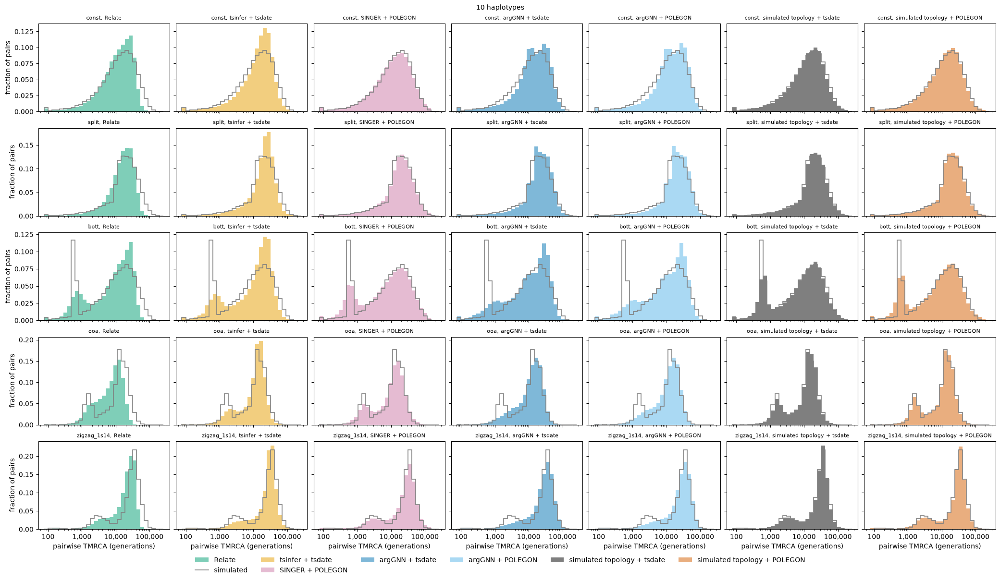

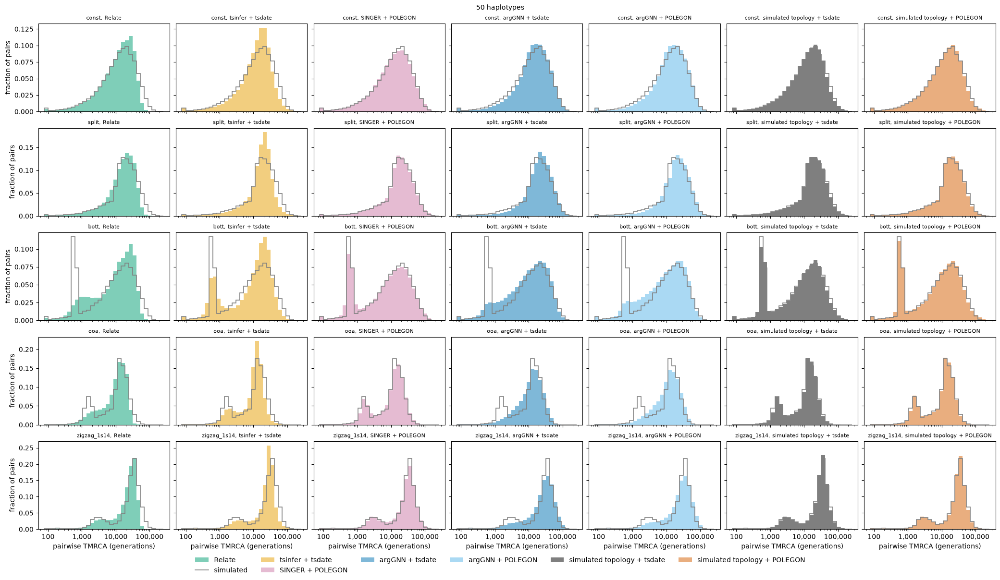

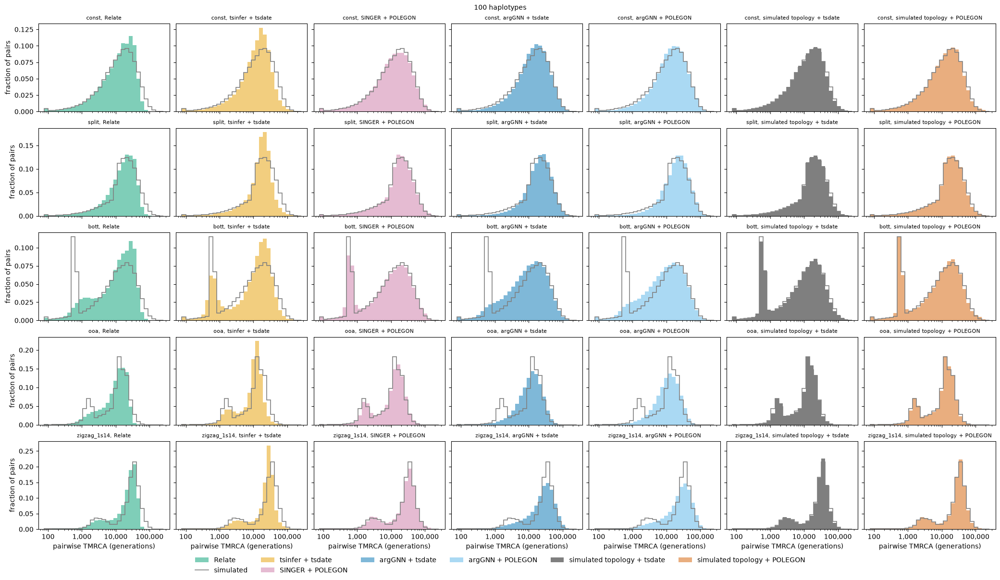

In [6]:
# Distribution of the pairwise TMRCA of each configuration under the simulated one, pooled over replicates.
for size in SIZES_SHOWN:
    plot_distributions(size)

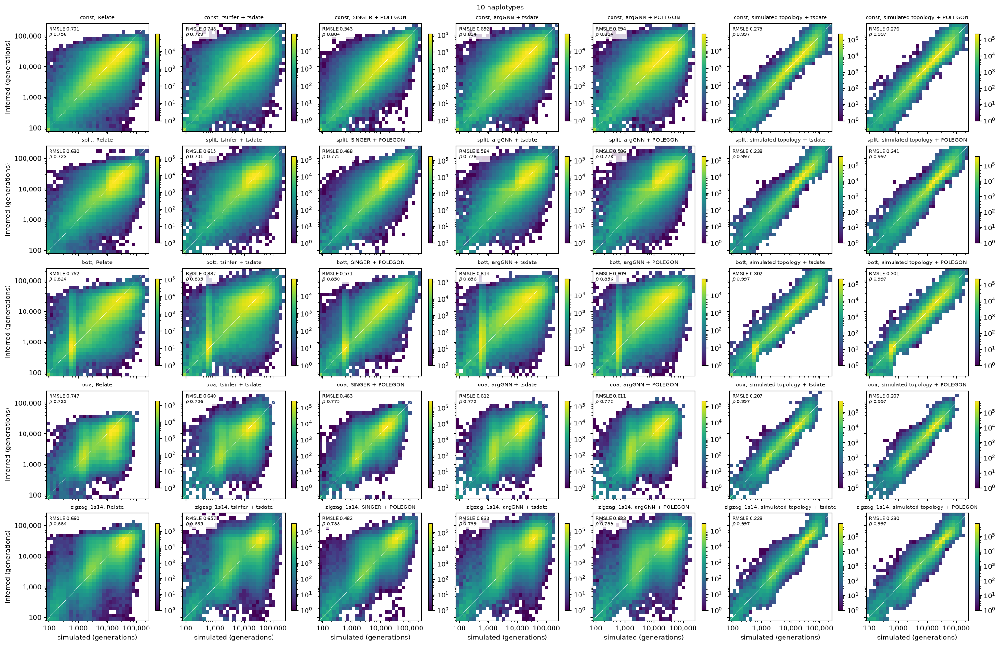

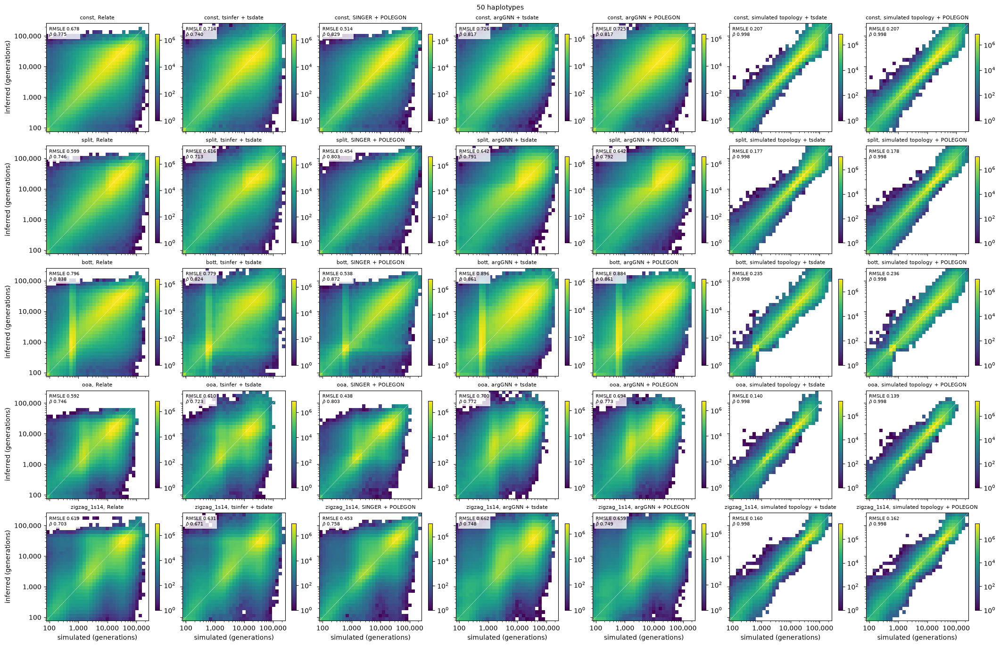

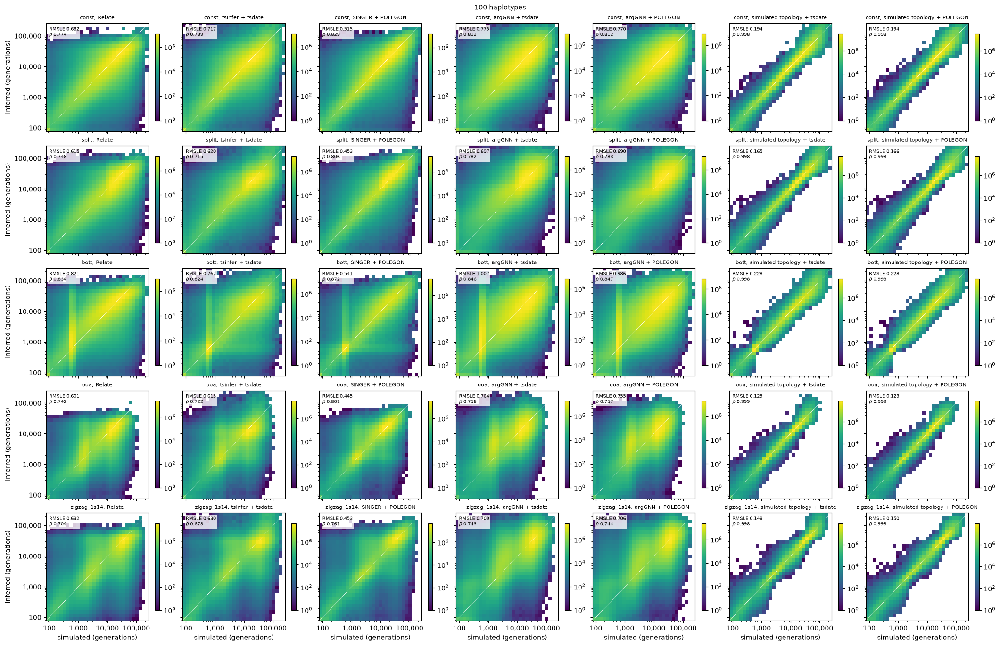

In [7]:
# 2D histograms of inferred against simulated pairwise TMRCA, pooled over replicates, with the means of RMSLE and rho.
for size in SIZES_SHOWN:
    plot_histograms_2d(
        size, "histogram_2d_count", {"RMSLE": "RMSLE", "rho_bar": r"$\bar\rho$"}
    )

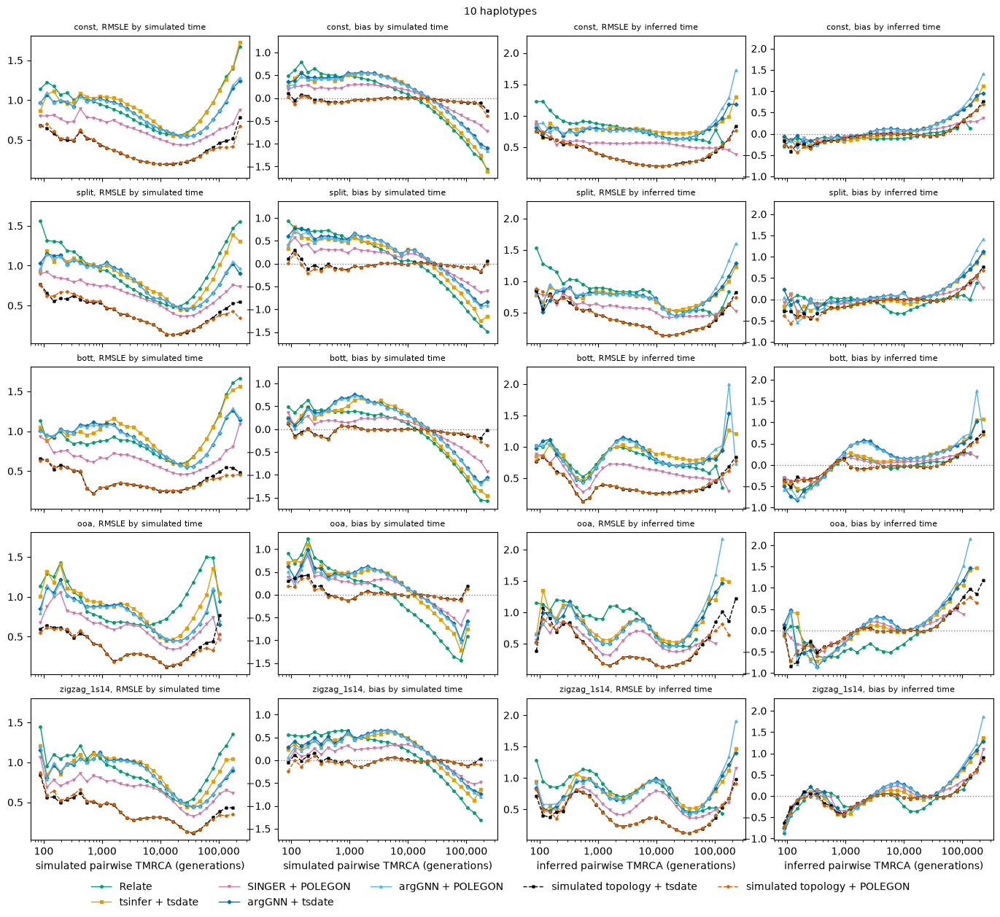

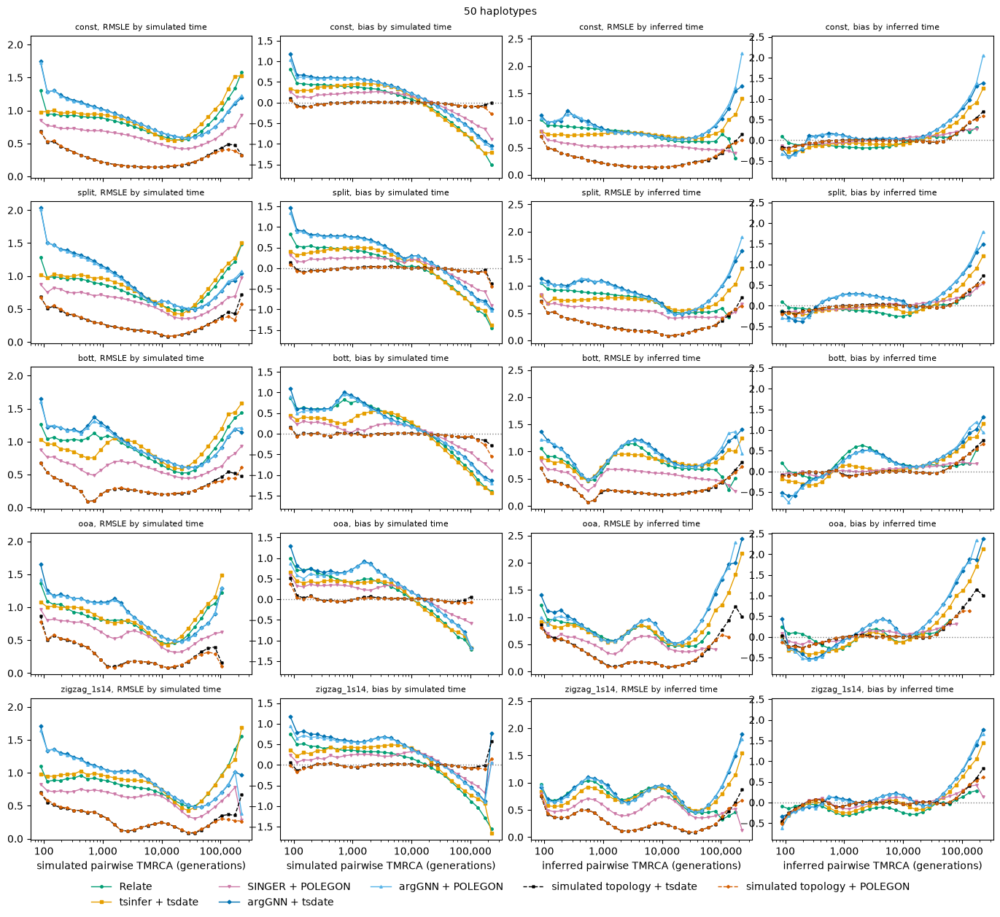

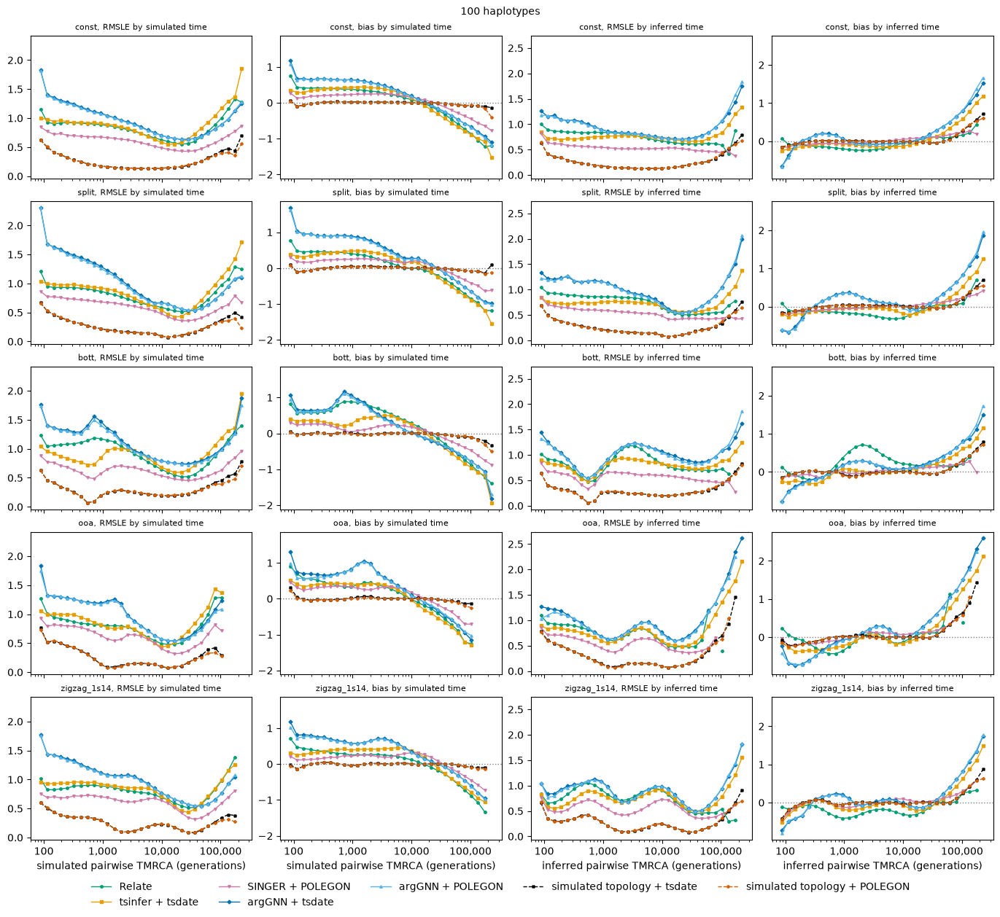

In [8]:
# RMSLE and bias of the pairwise TMRCA by simulated and by inferred time, pooled over replicates.
for size in SIZES_SHOWN:
    plot_errors_by_time(size)

In [9]:
# Mean ± standard deviation over replicates of RMSLE, bias, and L2 within and between populations.
pair_class_table(PAIR_CLASS_METRICS)

size                                                                                         10                  20                  30                  40                  50                  60                  70                  80   \
metric              method                             model pair class                                                                                                                                                                        
RMSLE               Relate                             split between A B            0.551 ± 0.14       0.511 ± 0.032       0.507 ± 0.014        0.51 ± 0.013       0.511 ± 0.012       0.514 ± 0.012       0.521 ± 0.013       0.523 ± 0.012   
                                                             within A               0.689 ± 0.11       0.649 ± 0.025       0.648 ± 0.013       0.661 ± 0.013       0.664 ± 0.011        0.668 ± 0.01       0.679 ± 0.012       0.681 ± 0.011   
                                                             within B              0.735 ± 0.072        0.69 ± 0.024       0.685 ± 0.022        0.692 ± 0.02       0.694 ± 0.023       0.685 ± 0.017       0.691 ± 0.015       0.692 ± 0.017   
                                                       ooa   between CEU CHB        0.743 ± 0.25        0.63 ± 0.056        0.609 ± 0.03       0.622 ± 0.027       0.618 ± 0.026       0.615 ± 0.024       0.625 ± 0.023       0.621 ± 0.025   
                                                             between YRI CEU        0.738 ± 0.31       0.596 ± 0.089       0.552 ± 0.037        0.547 ± 0.02       0.545 ± 0.018       0.546 ± 0.015       0.554 ± 0.015       0.552 ± 0.015   
                                                             between YRI CHB        0.735 ± 0.31       0.593 ± 0.088       0.548 ± 0.036        0.543 ± 0.02        0.54 ± 0.018       0.542 ± 0.014       0.548 ± 0.015       0.547 ± 0.015   
                                                             within CEU             0.771 ± 0.22        0.668 ± 0.06       0.641 ± 0.032       0.656 ± 0.029       0.654 ± 0.028        0.65 ± 0.025       0.662 ± 0.027        0.66 ± 0.025   
                                                             within CHB             0.755 ± 0.21       0.653 ± 0.047       0.633 ± 0.029       0.649 ± 0.025       0.645 ± 0.023        0.643 ± 0.02        0.652 ± 0.02       0.649 ± 0.022   
                                                             within YRI             0.786 ± 0.31       0.651 ± 0.093       0.606 ± 0.038       0.611 ± 0.027       0.604 ± 0.017       0.606 ± 0.021       0.613 ± 0.016       0.615 ± 0.019   
                    tsinfer + tsdate                   split between A B           0.524 ± 0.016       0.518 ± 0.013       0.519 ± 0.014       0.524 ± 0.014       0.527 ± 0.013       0.531 ± 0.014       0.534 ± 0.014       0.538 ± 0.014   
                                                             within A              0.663 ± 0.024       0.652 ± 0.015        0.65 ± 0.013        0.65 ± 0.014       0.649 ± 0.012        0.65 ± 0.012        0.65 ± 0.011       0.651 ± 0.011   
                                                             within B               0.76 ± 0.032       0.747 ± 0.029       0.746 ± 0.024       0.737 ± 0.019        0.741 ± 0.02       0.733 ± 0.018       0.734 ± 0.019        0.734 ± 0.02   
                                                       ooa   between CEU CHB       0.678 ± 0.036       0.644 ± 0.026       0.638 ± 0.027       0.631 ± 0.026       0.633 ± 0.025       0.633 ± 0.025       0.633 ± 0.025       0.634 ± 0.024   
                                                             between YRI CEU       0.588 ± 0.031       0.571 ± 0.024       0.565 ± 0.024        0.567 ± 0.02       0.571 ± 0.021       0.572 ± 0.016        0.577 ± 0.02       0.578 ± 0.022   
                                                             between YRI CHB       0.583 ± 0.028       0.571 ± 0.023       0.562 ± 0.021        0.564 ± 0.02    

## Coalescence rates

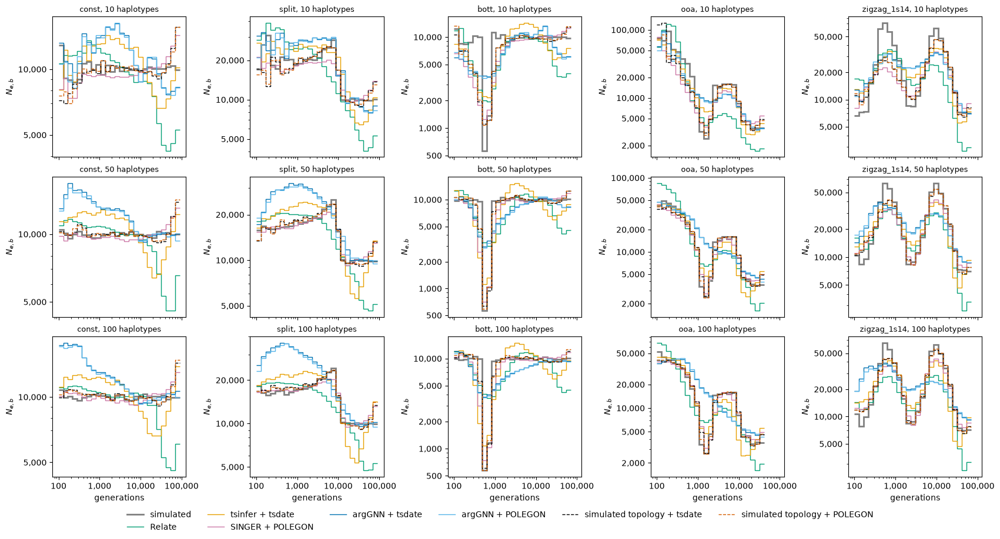

In [10]:
# N_e of all pairs in each bin, from the survival pooled over replicates.
plot_coalescence_rates()

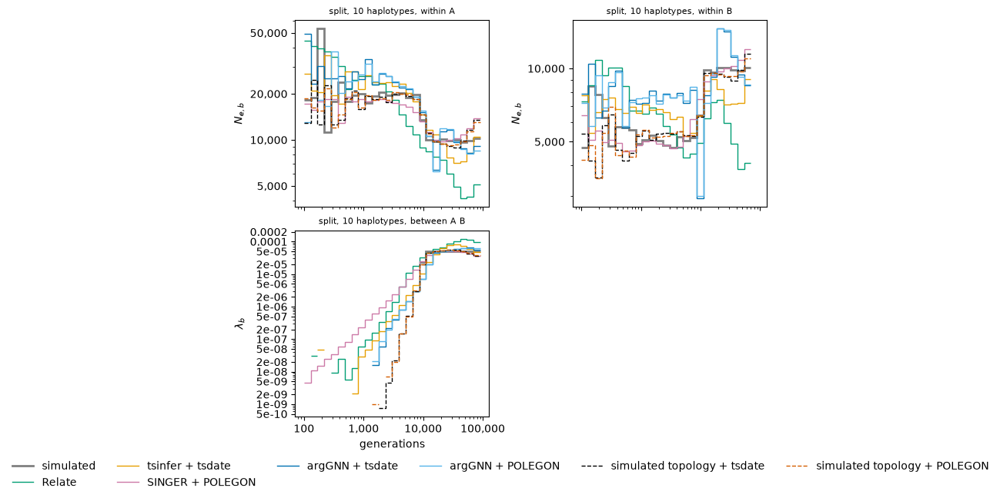

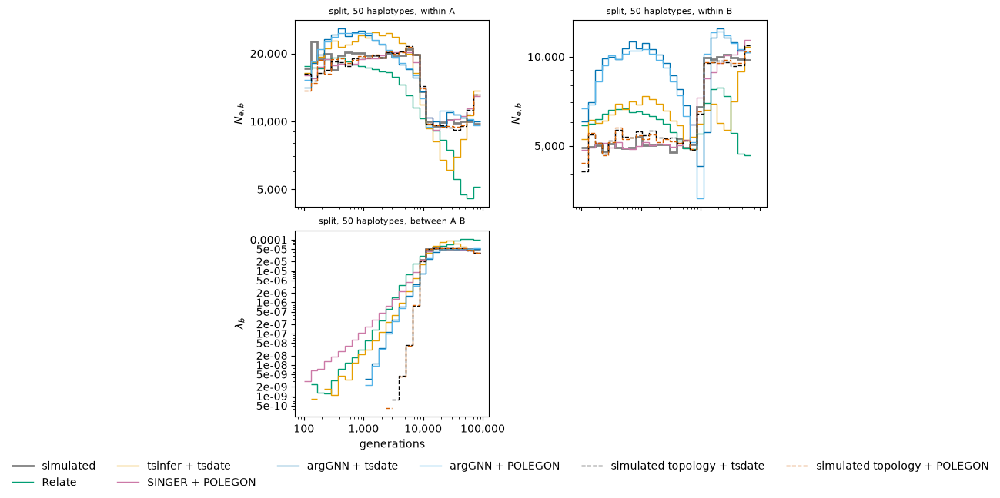

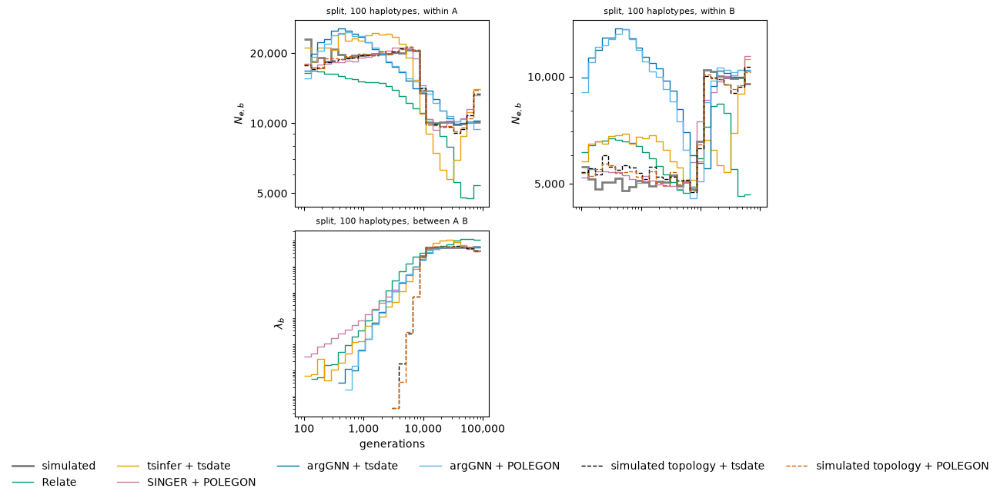

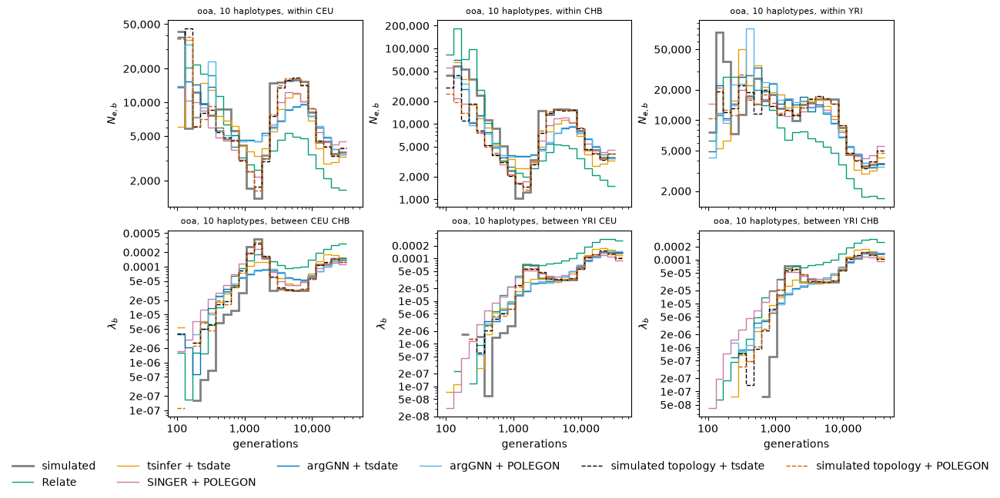

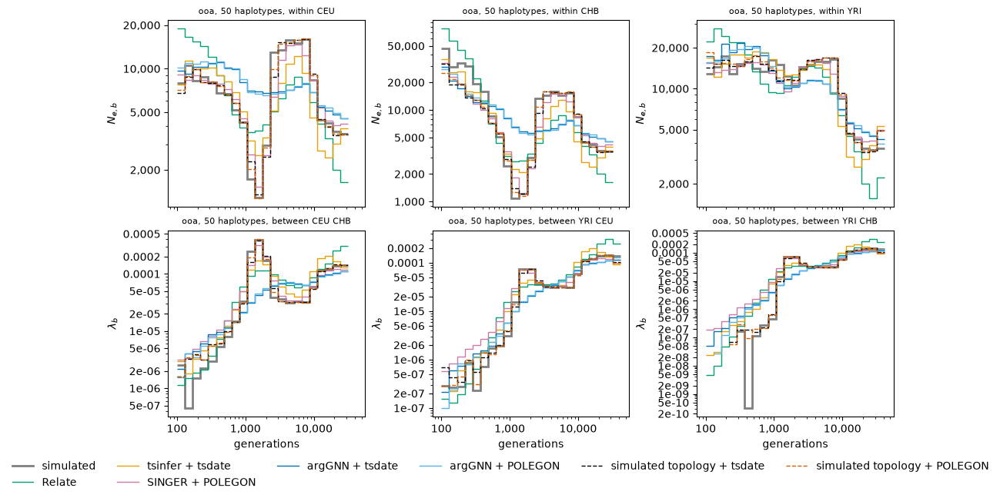

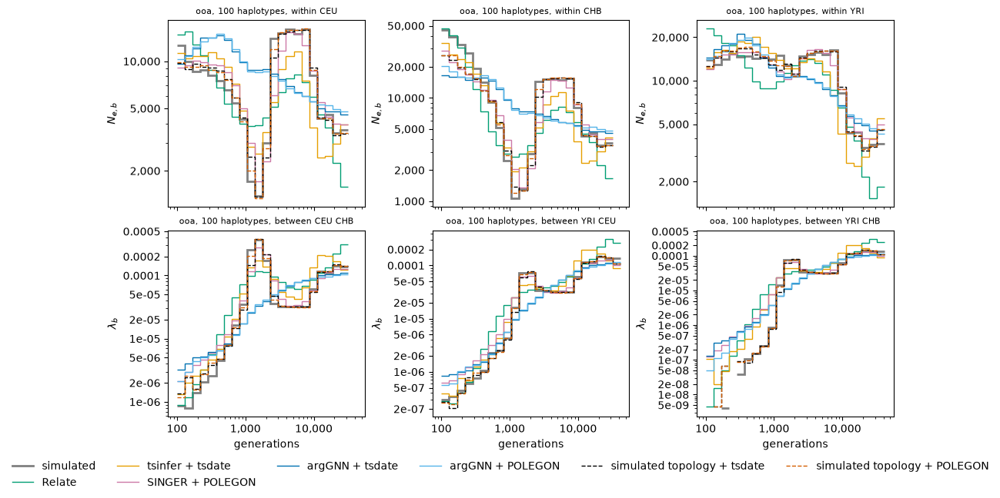

In [11]:
# N_e within and lambda_b between populations, for the models with more than one population.
for model in MODELS:
    if (
        pooled_df.loc[pooled_df["model"] == model, "pair_class"].str.startswith(
            "between_"
        )
    ).any():
        for size in SIZES_SHOWN:
            # A model and size without tables are left out.
            if (model, size) in SIMULATION_TOOL:
                plot_pair_class_rates(model, size)

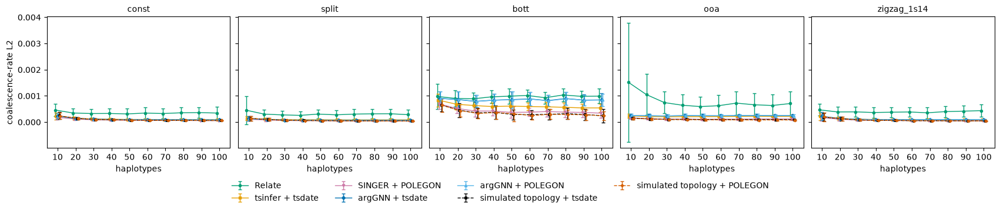

In [12]:
# Coalescence-rate L2 of all pairs against the sample size.
plot_metrics(RATE_METRICS)

In [13]:
# Mean ± standard deviation over replicates of the coalescence-rate L2 of all pairs.
metric_table(RATE_METRICS)

size                                                                               10                  20                  30                  40                  50                  60                  70                  80                  90   \
metric              method                             model                                                                                                                                                                                             
coalescence-rate L2 Relate                             const         0.00046 ± 0.00023  0.000347 ± 0.00016  0.000327 ± 0.00016  0.000331 ± 0.00019  0.000312 ± 0.00021  0.000345 ± 0.00021   0.000327 ± 0.0002  0.000355 ± 0.00022  0.000362 ± 0.00021   
                                                       split        0.000454 ± 0.00054  0.000305 ± 0.00017  0.000275 ± 0.00016  0.000257 ± 0.00015  0.000306 ± 0.00018  0.000278 ± 0.00018  0.000305 ± 0.00018  0.000316 ± 0.00018  0.000319 ± 0.00019   
                                                       bott         0.000979 ± 0.00049  0.000905 ± 0.00031  0.000888 ± 0.00023  0.000963 ± 0.00024   0.000989 ± 0.0003   0.00102 ± 0.00023   0.00093 ± 0.00022   0.00104 ± 0.00025  0.000983 ± 0.00022   
                                                       ooa            0.00152 ± 0.0023   0.00105 ± 0.00078  0.000745 ± 0.00042   0.000644 ± 0.0004  0.000593 ± 0.00037   0.000625 ± 0.0004  0.000724 ± 0.00045  0.000661 ± 0.00043  0.000634 ± 0.00043   
                                                       zigzag_1s14  0.000468 ± 0.00022   0.000388 ± 0.0002  0.000391 ± 0.00018   0.000366 ± 0.0002  0.000378 ± 0.00019  0.000387 ± 0.00018  0.000355 ± 0.00021    0.0004 ± 0.00022  0.000417 ± 0.00021   
                    tsinfer + tsdate                   const        0.000235 ± 0.00013  0.000151 ± 5.1e-05  0.000121 ± 3.1e-05   0.00011 ± 2.1e-05  0.000103 ± 1.6e-05  0.000102 ± 1.5e-05  9.79e-05 ± 1.3e-05  9.58e-05 ± 1.3e-05  9.35e-05 ± 1.3e-05   
                                                       split        0.000144 ± 7.7e-05  0.000107 ± 4.3e-05    9.49e-05 ± 2e-05  8.87e-05 ± 1.2e-05  9.09e-05 ± 1.3e-05  8.87e-05 ± 1.4e-05  8.61e-05 ± 9.6e-06  8.78e-05 ± 1.1e-05  8.82e-05 ± 1.2e-05   
                                                       bott         0.000841 ± 0.00025  0.000684 ± 0.00021  0.000632 ± 0.00017  0.000594 ± 0.00016   0.00061 ± 0.00023  0.000595 ± 0.00015  0.000583 ± 0.00018  0.000566 ± 0.00019  0.000542 ± 0.00015   
                                                       ooa          0.000238 ± 7.7e-05   0.00021 ± 4.6e-05  0.000204 ± 4.3e-05  0.000206 ± 4.1e-05  0.000208 ± 3.7e-05  0.000212 ± 3.8e-05  0.000217 ± 4.1e-05  0.000223 ± 4.5e-05  0.000218 ± 3.4e-05   
                                                       zigzag_1s14  0.000217 ± 0.00015  0.000139 ± 5.7e-05  0.000111 ± 2.6e-05  0.000102 ± 1.7e-05  9.98e-05 ± 1.4e-05  9.56e-05 ± 1.2e-05  9.62e-05 ± 1.1e-05  9.79e-05 ± 1.1e-05    9.72e-05 ± 1e-05   
                    SINGER + POLEGON                   const        0.000185 ± 9.4e-05  0.000118 ± 4.8e-05  8.79e-05 ± 3.2e-05  7.81e-05 ± 2.3e-05  6.97e-05 ± 1.6e-05  6.69e-05 ± 1.4e-05  6.21e-05 ± 1.3e-05  6.12e-05 ± 1.4e-05  5.84e-05 ± 1.3e-05   
                                                       split          0.000109 ± 6e-05  8.15e-05 ± 4.9e-05  6.14e-05 ± 1.8e-05  5.54e-05 ± 1.5e-05   5.4e-05 ± 1.5e-05  4.63e-05 ± 1.1e-05  4.39e-05 ± 8.7e-06  4.32e-05 ± 1.1e-05  4.24e-05 ± 9.5e-06   
                                                       bott         0.000695 ± 0.00021  0.000521 ± 0.00017  0.000423 ± 0.00021   0.00042 ± 0.00017   0.000372 ± 0.0002  0.000377 ± 0.00015   0.000402 ± 0.0002  0.000381 ± 0.00019  0.000369 ± 0.00018   
                                                       ooa          0.000164 ± 4.6e-05  0.000131 ± 3.6e-05  0.000111 ± 3.3e-05  0.000113 ± 2.9e-05    0.000103 ± 3e-05  0.000111 ± 3.7e-05  0.000109 ± 3.1e-05    0.000117 ± 4e-05  0.000117 ± 3.8e-05   


## Statistics in genomic windows

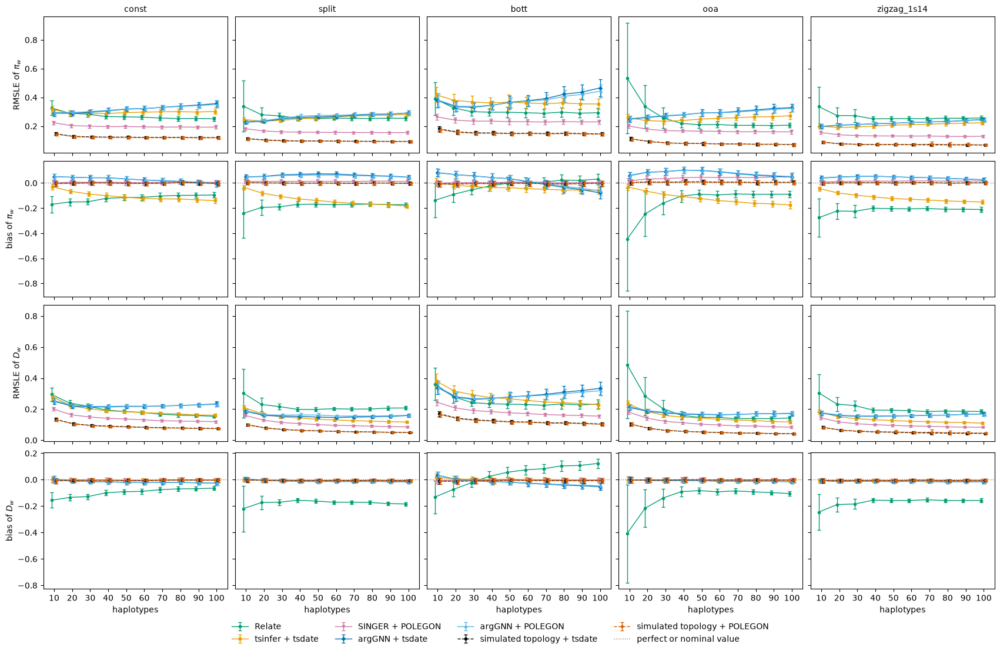

In [14]:
# Window metrics against the sample size, one row per metric and one column per model.
plot_metrics(WINDOW_METRICS)

In [15]:
# Mean ± standard deviation over replicates of the window metrics.
metric_table(WINDOW_METRICS)

size                                                                      10                 20                 30                 40                 50                60                70                 80                 90                 100
metric       method                             model                                                                                                                                                                                                 
RMSLE of π_w Relate                             const           0.327 ± 0.051       0.29 ± 0.021      0.283 ± 0.017      0.267 ± 0.016      0.265 ± 0.015     0.263 ± 0.015     0.257 ± 0.016      0.253 ± 0.017      0.254 ± 0.015      0.251 ± 0.015
                                                split            0.339 ± 0.18       0.28 ± 0.051       0.272 ± 0.02      0.256 ± 0.015      0.252 ± 0.014     0.256 ± 0.014     0.254 ± 0.013      0.253 ± 0.015      0.255 ± 0.015      0.255 ± 0.015
                                                bott             0.391 ± 0.11      0.328 ± 0.051      0.301 ± 0.028      0.297 ± 0.023      0.297 ± 0.036     0.294 ± 0.034     0.289 ± 0.027      0.298 ± 0.033       0.29 ± 0.029      0.294 ± 0.031
                                                ooa              0.535 ± 0.38       0.336 ± 0.15       0.258 ± 0.07       0.219 ± 0.03       0.21 ± 0.022     0.212 ± 0.019     0.206 ± 0.016      0.206 ± 0.016      0.204 ± 0.017      0.206 ± 0.017
                                                zigzag_1s14      0.336 ± 0.14      0.274 ± 0.056      0.273 ± 0.044      0.251 ± 0.018      0.252 ± 0.015     0.253 ± 0.015     0.252 ± 0.014      0.256 ± 0.016      0.255 ± 0.015      0.257 ± 0.016
             tsinfer + tsdate                   const           0.317 ± 0.027        0.29 ± 0.02      0.291 ± 0.019      0.288 ± 0.017      0.294 ± 0.017     0.297 ± 0.018       0.3 ± 0.018      0.301 ± 0.021      0.298 ± 0.019      0.303 ± 0.018
                                                split           0.245 ± 0.014      0.236 ± 0.011      0.239 ± 0.013      0.251 ± 0.015      0.256 ± 0.016     0.265 ± 0.015     0.271 ± 0.016      0.275 ± 0.018      0.276 ± 0.017      0.283 ± 0.015
                                                bott             0.42 ± 0.052      0.379 ± 0.046      0.368 ± 0.042      0.362 ± 0.038      0.367 ± 0.052     0.362 ± 0.041     0.357 ± 0.031      0.361 ± 0.035      0.356 ± 0.035      0.354 ± 0.037
                                                ooa              0.26 ± 0.026      0.239 ± 0.018      0.234 ± 0.019      0.239 ± 0.022      0.249 ± 0.021     0.255 ± 0.017     0.259 ± 0.021      0.265 ± 0.021      0.266 ± 0.021      0.273 ± 0.024
                                                zigzag_1s14     0.201 ± 0.017      0.191 ± 0.014      0.194 ± 0.012        0.2 ± 0.012      0.208 ± 0.015     0.209 ± 0.013     0.214 ± 0.013      0.218 ± 0.014      0.221 ± 0.014      0.223 ± 0.013
             SINGER + POLEGON                   const           0.225 ± 0.012      0.204 ± 0.012        0.2 ± 0.013      0.197 ± 0.012      0.197 ± 0.012      0.196 ± 0.01     0.193 ± 0.011      0.194 ± 0.011      0.193 ± 0.012      0.194 ± 0.011
                                                split            0.182 ± 0.01     0.167 ± 0.0088      0.16 ± 0.0091     0.159 ± 0.0087     0.157 ± 0.0086    0.157 ± 0.0094    0.156 ± 0.0083     0.156 ± 0.0087      0.155 ± 0.008     0.155 ± 0.0099
                                                bott            0.265 ± 0.019      0.242 ± 0.017      0.235 ± 0.018      0.235 ± 0.017      0.232 ± 0.019     0.231 ± 0.018     0.229 ± 0.016      0.231 ± 0.016       0.23 ± 0.016       0.23 ± 0.016
                                                ooa             0.201 ± 0.015       0.18 ± 0.013      0.169 ± 0.012      0.167 ± 0.011      0.165 ± 0.012     0.164 ± 0.012      0.16 ± 0.012      0.161 ± 0.012       0.16 ± 0.011      0.161 ± 0.013
                                                

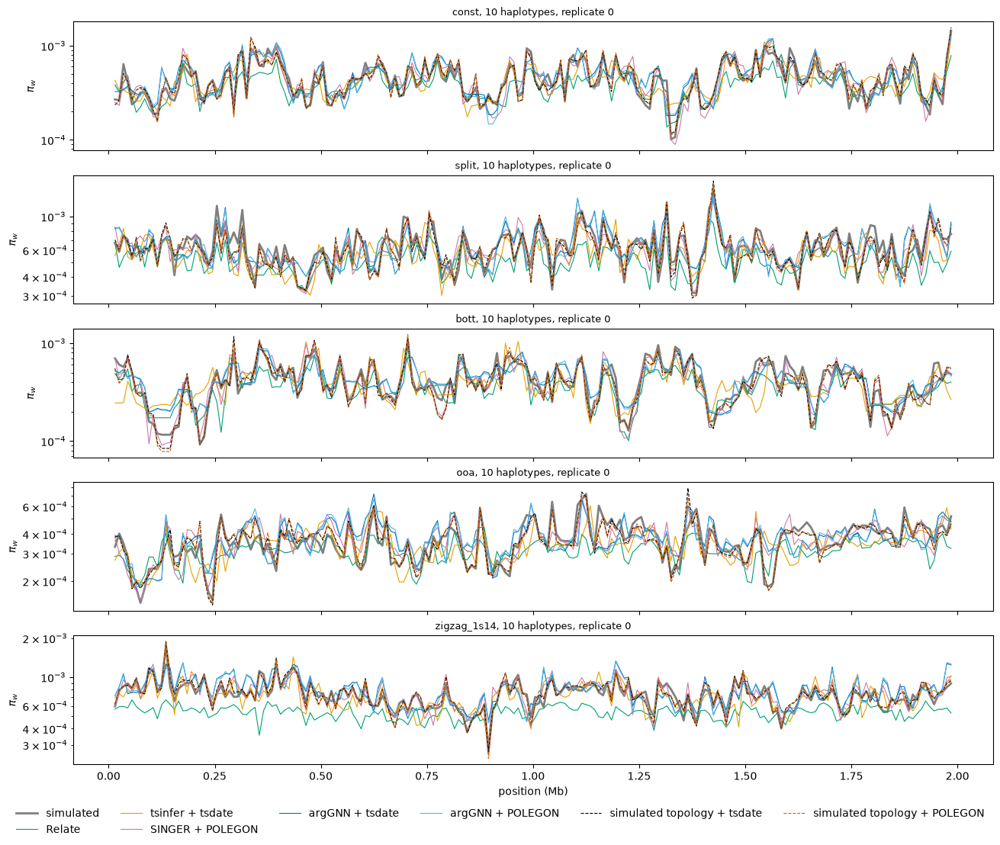

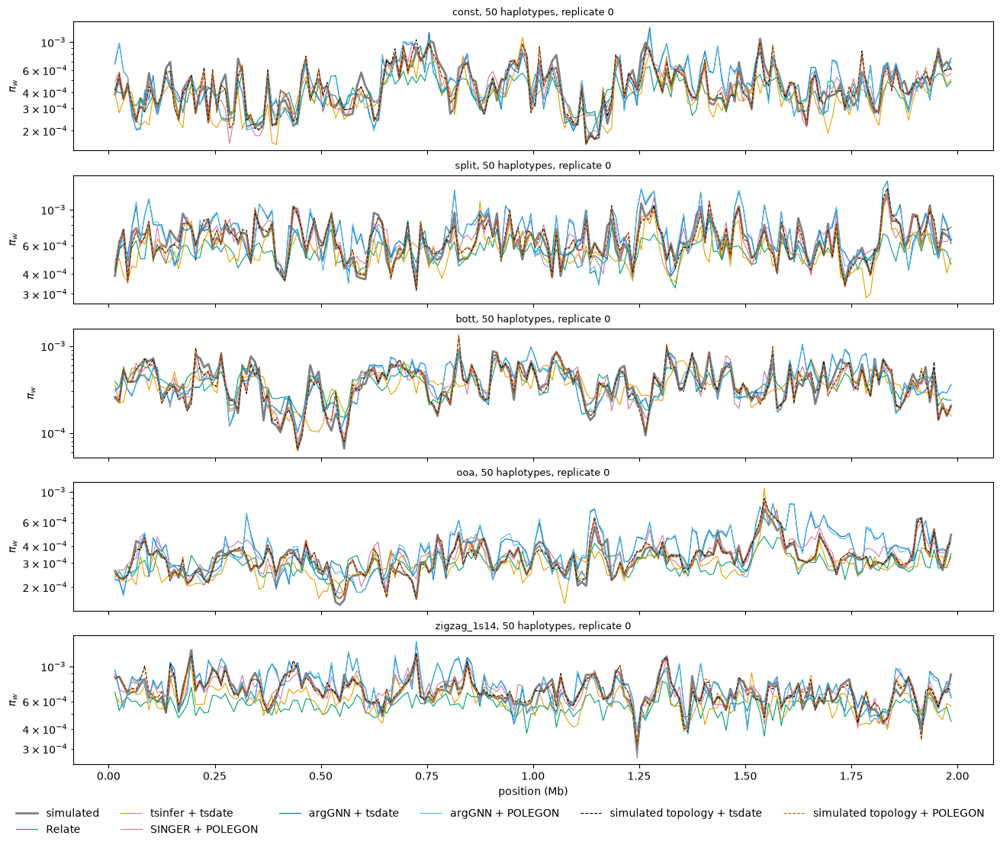

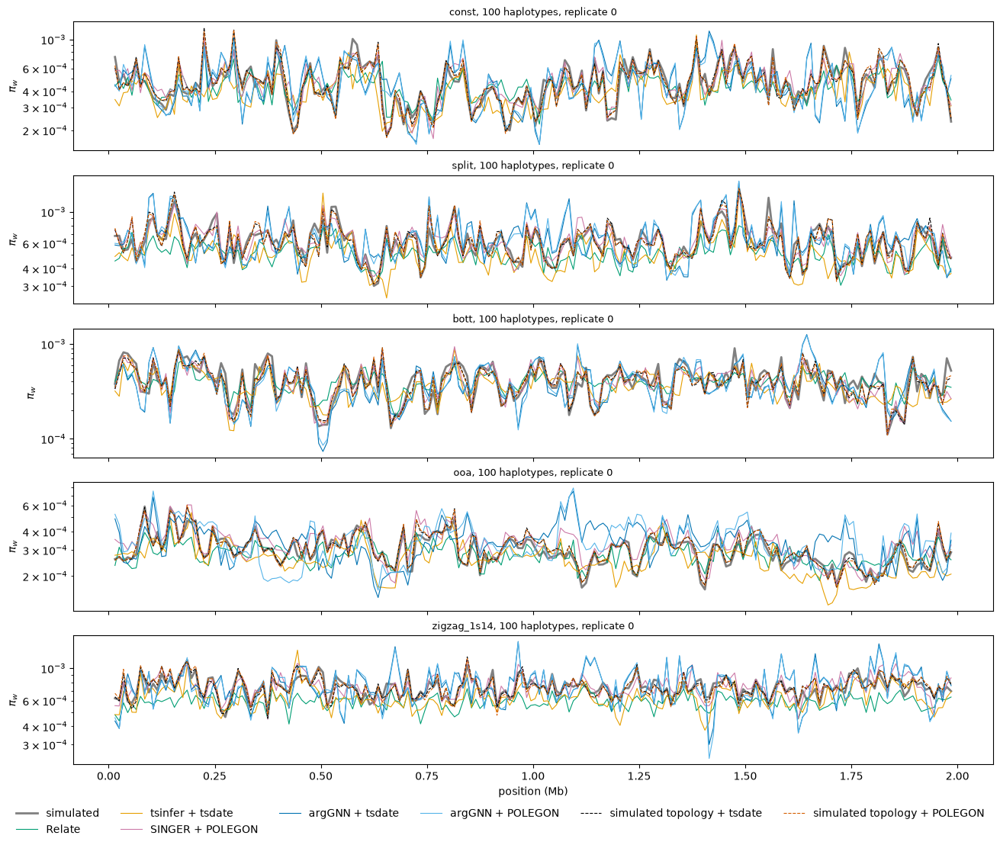

In [16]:
# pi_w in 10 kb windows along the genome of replicate 0.
for size in SIZES_SHOWN:
    plot_diversity_along_genome(size)

## Mutation ages

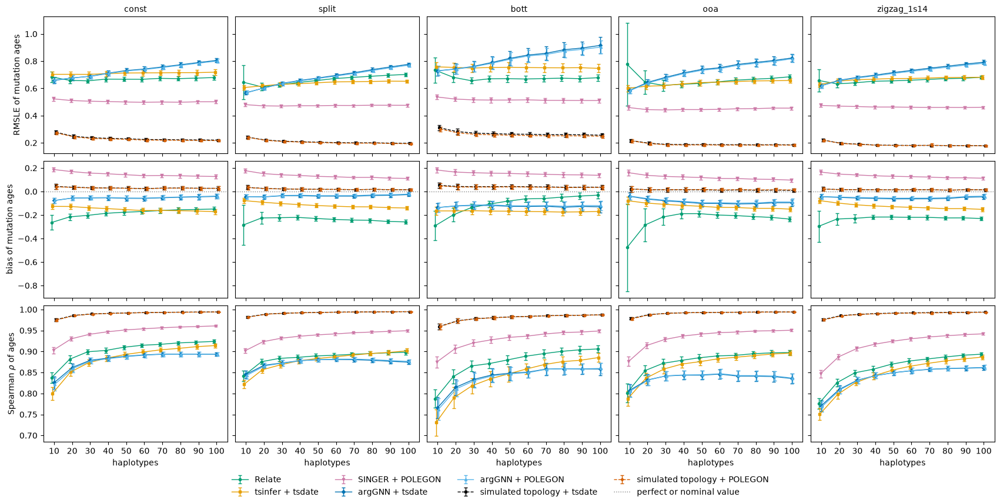

In [17]:
# Mutation age metrics against the sample size, one row per metric and one column per model.
plot_metrics(AGE_METRICS)

In [18]:
# Mean ± standard deviation over replicates of the mutation age metrics.
metric_table(AGE_METRICS)

size                                                                               10               20               30               40               50               60               70               80               90               100
metric                 method                             model                                                                                                                                                                                
RMSLE of mutation ages Relate                             const          0.684 ± 0.037    0.659 ± 0.021    0.655 ± 0.015    0.668 ± 0.017    0.667 ± 0.015    0.666 ± 0.017    0.673 ± 0.014    0.671 ± 0.015    0.675 ± 0.016    0.679 ± 0.015
                                                          split           0.645 ± 0.13    0.611 ± 0.028    0.625 ± 0.015    0.643 ± 0.014    0.656 ± 0.012    0.671 ± 0.013     0.68 ± 0.012    0.688 ± 0.013    0.696 ± 0.014    0.702 ± 0.013
                                                          bott           0.733 ± 0.091    0.681 ± 0.038    0.656 ± 0.022     0.67 ± 0.021    0.671 ± 0.027    0.669 ± 0.022    0.672 ± 0.024    0.675 ± 0.021    0.671 ± 0.023    0.678 ± 0.023
                                                          ooa              0.777 ± 0.3    0.645 ± 0.088    0.622 ± 0.041     0.63 ± 0.023    0.636 ± 0.019    0.647 ± 0.019     0.66 ± 0.018    0.667 ± 0.019    0.674 ± 0.019    0.685 ± 0.016
                                                          zigzag_1s14     0.658 ± 0.08    0.633 ± 0.026    0.641 ± 0.019    0.652 ± 0.012    0.655 ± 0.013    0.659 ± 0.013    0.665 ± 0.015    0.671 ± 0.014    0.674 ± 0.014    0.681 ± 0.012
                       tsinfer + tsdate                   const          0.703 ± 0.021     0.703 ± 0.02    0.703 ± 0.019    0.708 ± 0.019    0.713 ± 0.017    0.714 ± 0.021    0.714 ± 0.018    0.715 ± 0.021    0.715 ± 0.019    0.719 ± 0.021
                                                          split          0.606 ± 0.016    0.618 ± 0.015     0.63 ± 0.013    0.634 ± 0.014    0.641 ± 0.013    0.647 ± 0.014    0.649 ± 0.013     0.65 ± 0.013    0.653 ± 0.012    0.652 ± 0.012
                                                          bott           0.758 ± 0.032    0.754 ± 0.033    0.749 ± 0.032    0.754 ± 0.031    0.755 ± 0.036     0.753 ± 0.03    0.751 ± 0.033    0.751 ± 0.032    0.752 ± 0.027     0.747 ± 0.03
                                                          ooa              0.6 ± 0.024    0.616 ± 0.022     0.62 ± 0.019    0.632 ± 0.019    0.642 ± 0.021     0.646 ± 0.02     0.65 ± 0.019     0.655 ± 0.02    0.656 ± 0.017    0.658 ± 0.019
                                                          zigzag_1s14    0.628 ± 0.019    0.652 ± 0.019    0.663 ± 0.014    0.667 ± 0.015    0.672 ± 0.016    0.672 ± 0.014    0.676 ± 0.015     0.68 ± 0.014    0.681 ± 0.015    0.681 ± 0.013
                       SINGER + POLEGON                   const          0.523 ± 0.014    0.511 ± 0.013    0.505 ± 0.013    0.503 ± 0.013      0.5 ± 0.013    0.497 ± 0.012      0.5 ± 0.013    0.498 ± 0.012    0.501 ± 0.011    0.501 ± 0.012
                                                          split           0.48 ± 0.012     0.471 ± 0.01      0.47 ± 0.01    0.472 ± 0.011    0.472 ± 0.009    0.474 ± 0.009   0.474 ± 0.0085   0.476 ± 0.0092   0.476 ± 0.0091   0.475 ± 0.0099
                                                          bott           0.537 ± 0.016    0.521 ± 0.016    0.515 ± 0.016    0.514 ± 0.018    0.514 ± 0.015    0.515 ± 0.017    0.512 ± 0.017    0.512 ± 0.017    0.511 ± 0.015     0.51 ± 0.016
                                                          ooa            0.459 ± 0.016    0.444 ± 0.014    0.441 ± 0.013    0.444 ± 0.012    0.444 ± 0.012     0.446 ± 0.01      0.45 ± 0.01   0.451 ± 0.0091   0.455 ± 0.0093    0.455 ± 0.011
                                                          zigzag_1s14    0.475 ± 0.013      0.47 ± 0.01   0.466 ± 0.0097     0.463 ± 0.01   0.463 ± 0.0094   0.4

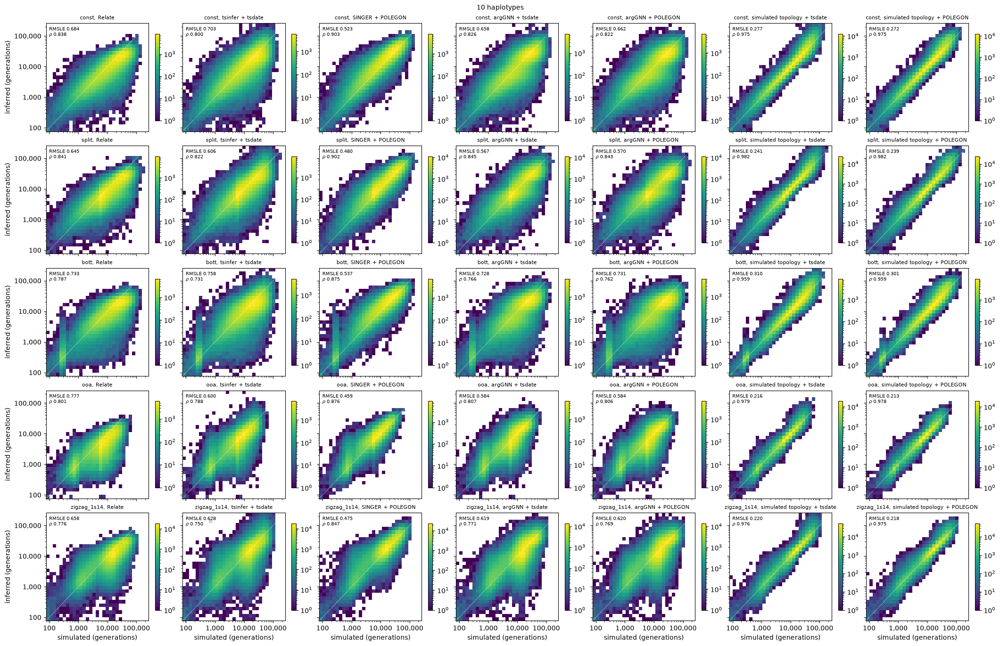

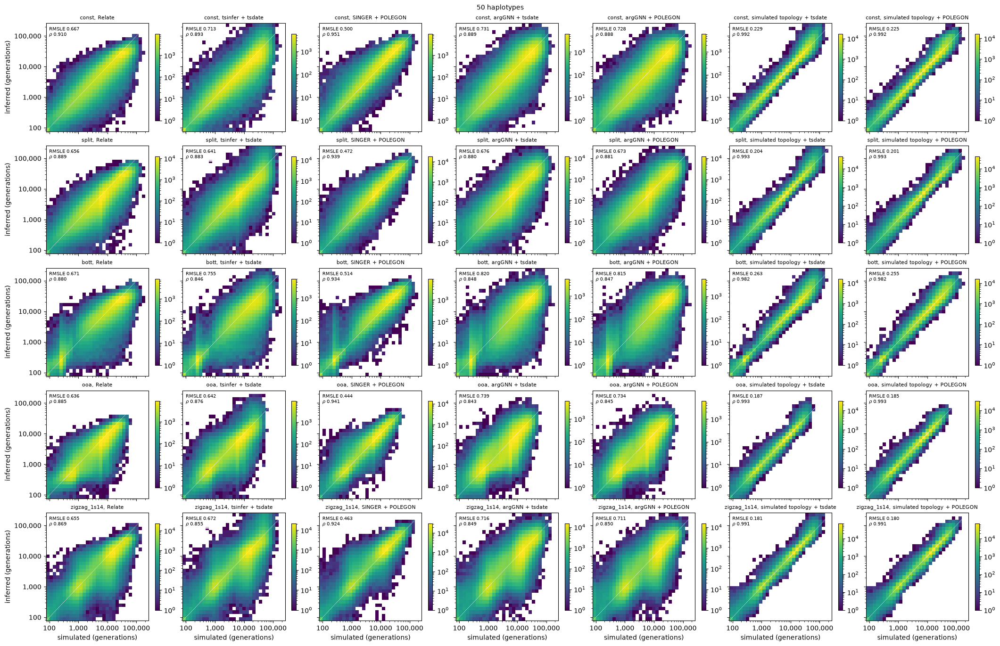

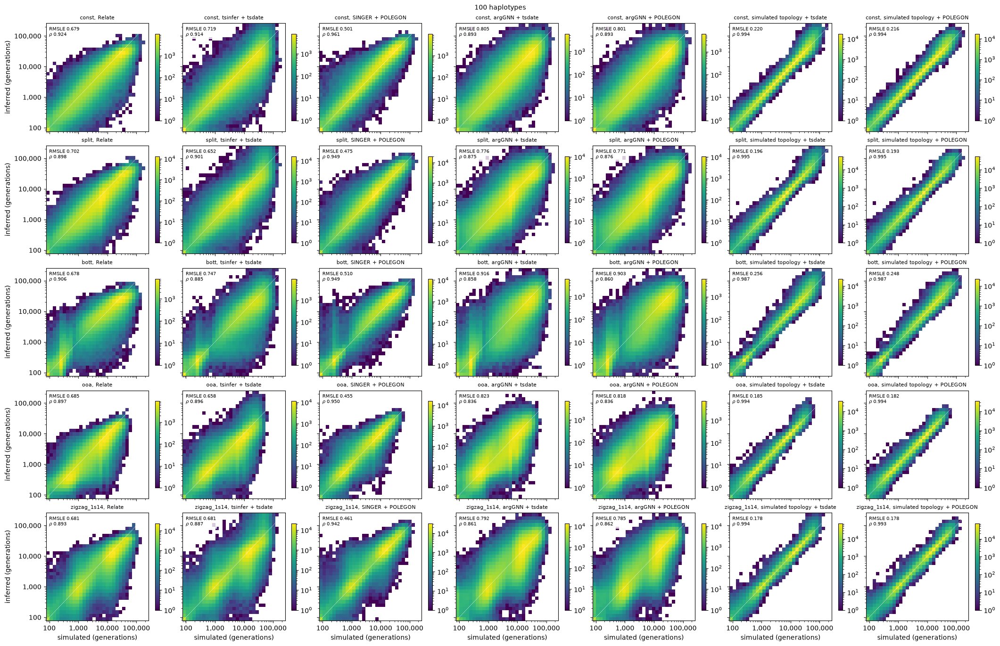

In [19]:
# 2D histograms of inferred against simulated mutation ages, pooled over replicates, with the means of RMSLE and rho.
for size in SIZES_SHOWN:
    plot_histograms_2d(
        size, "histogram_2d_count_a", {"RMSLE_a": "RMSLE", "rho_a": r"$\rho$"}
    )

## Calibration

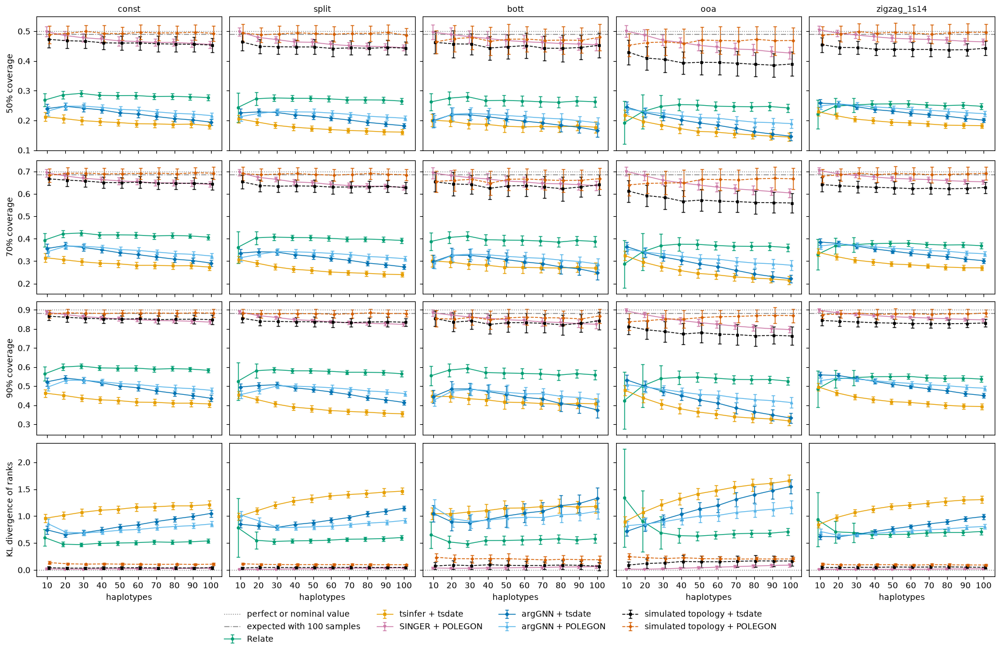

In [20]:
# Coverage and KL divergence of the ranks against the sample size, with the nominal and the expected values.
plot_metrics(CALIBRATION_METRICS)

In [21]:
# Mean ± standard deviation over replicates of the calibration metrics.
metric_table(CALIBRATION_METRICS)

size                                                                               10                20                30               40               50               60               70               80               90               100
metric                 method                             model                                                                                                                                                                                  
50% coverage           Relate                             const          0.269 ± 0.022     0.286 ± 0.013     0.291 ± 0.011    0.284 ± 0.011    0.284 ± 0.011     0.284 ± 0.01    0.28 ± 0.0097   0.281 ± 0.0098    0.28 ± 0.0096     0.277 ± 0.01
                                                          split           0.244 ± 0.05     0.273 ± 0.021      0.276 ± 0.01   0.274 ± 0.0099   0.274 ± 0.0091     0.273 ± 0.01   0.269 ± 0.0091     0.269 ± 0.01     0.269 ± 0.01     0.265 ± 0.01
                                                          bott           0.263 ± 0.028     0.275 ± 0.021      0.28 ± 0.015    0.266 ± 0.016    0.267 ± 0.018    0.266 ± 0.016    0.263 ± 0.017    0.261 ± 0.017    0.265 ± 0.016    0.263 ± 0.017
                                                          ooa            0.192 ± 0.072     0.229 ± 0.058     0.247 ± 0.037     0.253 ± 0.02    0.252 ± 0.017    0.248 ± 0.014    0.247 ± 0.014    0.246 ± 0.015    0.247 ± 0.014    0.242 ± 0.014
                                                          zigzag_1s14    0.221 ± 0.048     0.248 ± 0.026     0.252 ± 0.024    0.255 ± 0.012   0.256 ± 0.0095    0.256 ± 0.011   0.252 ± 0.0092      0.25 ± 0.01   0.252 ± 0.0093     0.248 ± 0.01
                       tsinfer + tsdate                   const          0.212 ± 0.015     0.206 ± 0.013     0.199 ± 0.012    0.196 ± 0.012    0.193 ± 0.012     0.189 ± 0.01    0.188 ± 0.011    0.187 ± 0.011    0.188 ± 0.011    0.183 ± 0.012
                                                          split          0.206 ± 0.013     0.195 ± 0.011      0.184 ± 0.01    0.177 ± 0.011   0.173 ± 0.0098    0.17 ± 0.0092   0.166 ± 0.0083   0.165 ± 0.0094   0.162 ± 0.0096   0.161 ± 0.0085
                                                          bott           0.201 ± 0.021     0.197 ± 0.018     0.188 ± 0.016    0.187 ± 0.019     0.181 ± 0.02    0.178 ± 0.019     0.18 ± 0.016    0.179 ± 0.018    0.182 ± 0.016    0.177 ± 0.018
                                                          ooa            0.219 ± 0.017     0.197 ± 0.016     0.185 ± 0.015    0.173 ± 0.016    0.163 ± 0.014    0.161 ± 0.015    0.155 ± 0.013    0.151 ± 0.013    0.147 ± 0.012    0.144 ± 0.014
                                                          zigzag_1s14    0.229 ± 0.014      0.216 ± 0.01    0.205 ± 0.0089     0.199 ± 0.01   0.194 ± 0.0092   0.192 ± 0.0071   0.188 ± 0.0087   0.184 ± 0.0089   0.183 ± 0.0085   0.183 ± 0.0083
                       SINGER + POLEGON                   const          0.499 ± 0.017     0.486 ± 0.014     0.478 ± 0.014    0.474 ± 0.013    0.468 ± 0.016    0.465 ± 0.014    0.462 ± 0.012    0.463 ± 0.012    0.459 ± 0.012    0.456 ± 0.012
                                                          split          0.499 ± 0.014     0.479 ± 0.012     0.472 ± 0.011    0.464 ± 0.011    0.463 ± 0.011    0.456 ± 0.011    0.452 ± 0.011     0.45 ± 0.011     0.448 ± 0.01    0.445 ± 0.011
                                                          bott           0.497 ± 0.025     0.489 ± 0.023     0.482 ± 0.021    0.476 ± 0.024    0.469 ± 0.021    0.465 ± 0.021    0.462 ± 0.021    0.459 ± 0.022     0.457 ± 0.02    0.455 ± 0.019
                                                          ooa             0.501 ± 0.02      0.487 ± 0.02      0.47 ± 0.018    0.462 ± 0.017    0.453 ± 0.018    0.447 ± 0.018      0.44 ± 0.02    0.438 ± 0.018    0.431 ± 0.017    0.427 ± 0.019
                                                          zigzag_1s14    0.505 ± 0.014     0.494 ± 0.011     0.488 ± 0.011    0.

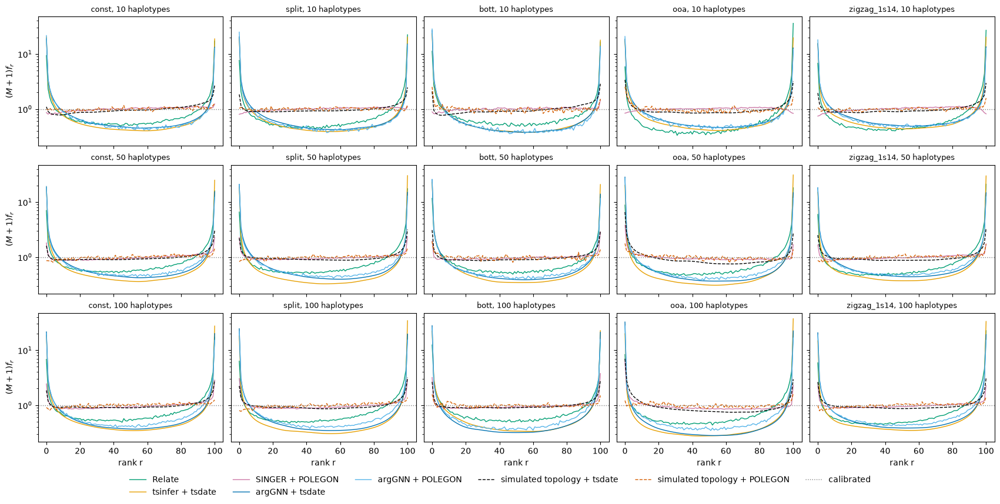

In [22]:
# Rank fractions times M + 1, means over replicates.
plot_ranks()

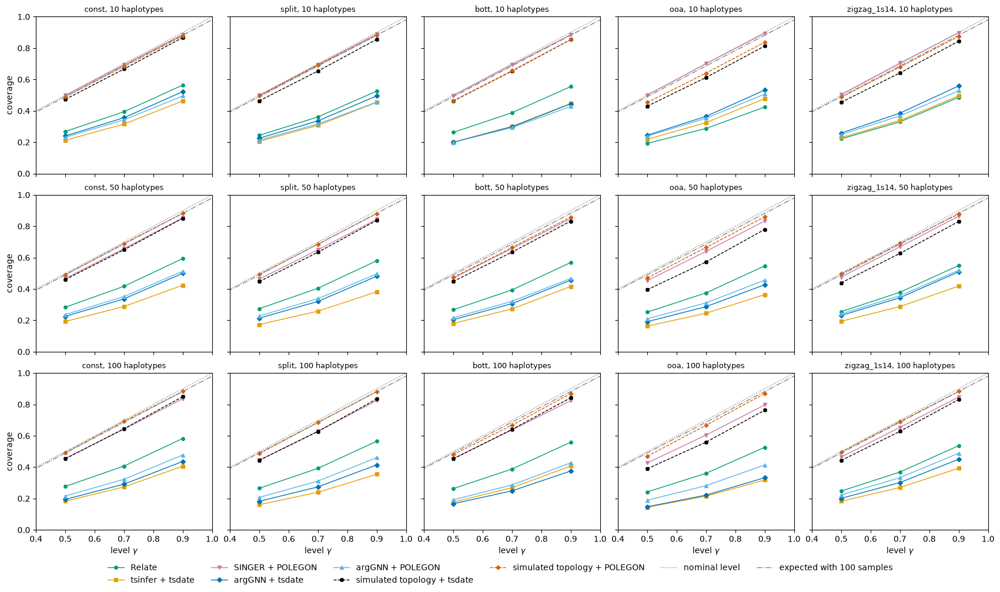

In [23]:
# Coverage against the level of the interval, means over replicates.
plot_coverage()

## Topology

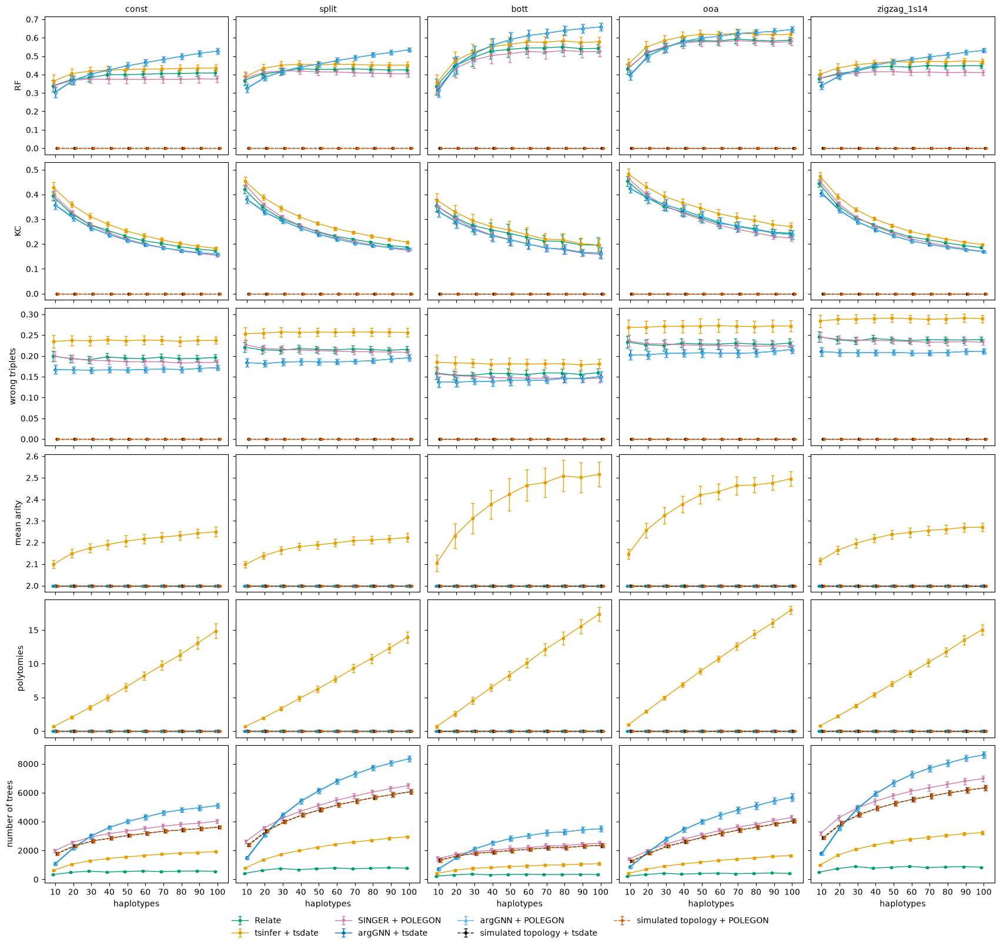

In [24]:
# Topology metrics against the sample size, one row per metric and one column per model.
plot_metrics(TOPOLOGY_METRICS)

In [25]:
# Mean ± standard deviation over replicates of the topology metrics.
metric_table(TOPOLOGY_METRICS)

size                                                                           10                  20                  30                  40                  50                  60                  70                  80                  90   \
metric          method                             model                                                                                                                                                                                             
RF              Relate                             const             0.339 ± 0.031       0.371 ± 0.024       0.383 ± 0.022       0.399 ± 0.021         0.4 ± 0.022       0.402 ± 0.018       0.405 ± 0.017       0.405 ± 0.017       0.408 ± 0.018   
                                                   split             0.369 ± 0.026        0.403 ± 0.02       0.415 ± 0.019       0.432 ± 0.018       0.428 ± 0.018       0.428 ± 0.014       0.432 ± 0.016       0.428 ± 0.015       0.425 ± 0.015   
                                                   bott              0.335 ± 0.044        0.444 ± 0.05        0.49 ± 0.044        0.526 ± 0.04       0.536 ± 0.041       0.545 ± 0.032       0.545 ± 0.031        0.55 ± 0.031       0.541 ± 0.029   
                                                   ooa                0.43 ± 0.029       0.514 ± 0.033       0.544 ± 0.028       0.578 ± 0.026       0.585 ± 0.022       0.582 ± 0.021       0.592 ± 0.022       0.587 ± 0.017       0.582 ± 0.017   
                                                   zigzag_1s14       0.378 ± 0.022       0.404 ± 0.022       0.417 ± 0.019       0.441 ± 0.016       0.444 ± 0.016       0.441 ± 0.016       0.449 ± 0.016       0.446 ± 0.015       0.448 ± 0.016   
                tsinfer + tsdate                   const             0.364 ± 0.035       0.405 ± 0.026       0.418 ± 0.023       0.424 ± 0.024       0.427 ± 0.024       0.429 ± 0.019         0.43 ± 0.02       0.433 ± 0.019        0.434 ± 0.02   
                                                   split             0.389 ± 0.028       0.434 ± 0.023        0.45 ± 0.022        0.456 ± 0.02       0.453 ± 0.019       0.456 ± 0.016       0.455 ± 0.017       0.452 ± 0.017       0.451 ± 0.016   
                                                   bott              0.354 ± 0.046        0.474 ± 0.05       0.521 ± 0.046       0.551 ± 0.042        0.563 ± 0.04       0.577 ± 0.033       0.576 ± 0.032       0.584 ± 0.033       0.574 ± 0.031   
                                                   ooa                0.457 ± 0.03       0.549 ± 0.032       0.585 ± 0.028       0.607 ± 0.026       0.619 ± 0.023        0.617 ± 0.02       0.624 ± 0.024       0.621 ± 0.018       0.616 ± 0.018   
                                                   zigzag_1s14       0.401 ± 0.023       0.436 ± 0.024       0.454 ± 0.021       0.462 ± 0.017        0.47 ± 0.017       0.468 ± 0.018       0.471 ± 0.017       0.469 ± 0.016       0.474 ± 0.016   
                SINGER + POLEGON                   const              0.34 ± 0.031       0.369 ± 0.024       0.375 ± 0.021        0.373 ± 0.02       0.374 ± 0.021       0.373 ± 0.017       0.374 ± 0.019       0.373 ± 0.017        0.376 ± 0.02   
                                                   split             0.382 ± 0.026        0.412 ± 0.02       0.419 ± 0.019       0.419 ± 0.018       0.414 ± 0.017       0.414 ± 0.014        0.41 ± 0.015       0.407 ± 0.016       0.404 ± 0.014   
                                                   bott               0.327 ± 0.04       0.435 ± 0.051       0.478 ± 0.043       0.503 ± 0.043       0.513 ± 0.045       0.525 ± 0.034       0.522 ± 0.035       0.531 ± 0.033       0.525 ± 0.031   
                                                   ooa                0.44 ± 0.027        0.52 ± 0.033       0.553 ± 0.028       0.572 ± 0.029       0.579 ± 0.025       0.577 ± 0.022       0.584 ± 0.025        0.58 ± 0.019        0.575 ± 0.02   
                                                   zigzag_1s14  

## Run time

In [26]:
# Mean ± standard deviation over replicates of the minutes per data set of each method.
run_time_table()

size                                                         10               20               30               40               50               60               70               80               90               100
method                             model                                                                                                                                                                                 
Relate                             const             2.03 ± 0.23      3.44 ± 0.38      4.58 ± 0.51      4.61 ± 0.45      5.46 ± 0.57      6.49 ± 0.67      6.55 ± 0.69      7.55 ± 0.78      8.46 ± 0.93         9 ± 0.94
                                   split             2.45 ± 0.28      4.51 ± 0.43        6.1 ± 0.6       6.03 ± 0.6      7.39 ± 0.75      8.71 ± 0.88      9.17 ± 0.88       10.4 ± 1.1       11.8 ± 1.2       12.3 ± 1.3
                                   bott              1.36 ± 0.24      2.23 ± 0.33      2.96 ± 0.44      2.79 ± 0.39      3.31 ± 0.52       3.78 ± 0.5      4.05 ± 0.53      4.45 ± 0.67       5.05 ± 0.6      5.23 ± 0.65
                                   ooa                1.3 ± 0.18      2.35 ± 0.28      3.31 ± 0.38      3.14 ± 0.36      3.91 ± 0.39      4.59 ± 0.51      4.67 ± 0.49      5.41 ± 0.58      6.32 ± 0.56      6.45 ± 0.71
                                   zigzag_1s14        2.99 ± 0.3      5.39 ± 0.54      7.21 ± 0.74      7.01 ± 0.72      8.53 ± 0.86         10.1 ± 1       10.3 ± 1.1         12 ± 1.1       13.3 ± 1.3         14 ± 1.5
tsinfer + tsdate                   const         0.0157 ± 0.0048  0.0277 ± 0.0057  0.0361 ± 0.0058  0.0347 ± 0.0044  0.0406 ± 0.0044   0.056 ± 0.0083  0.0599 ± 0.0061  0.0606 ± 0.0052  0.0674 ± 0.0056  0.0751 ± 0.0053
                                   split         0.0206 ± 0.0057  0.0293 ± 0.0041  0.0433 ± 0.0046  0.0575 ± 0.0049   0.065 ± 0.0065  0.0827 ± 0.0057  0.0918 ± 0.0067   0.102 ± 0.0056   0.108 ± 0.0073    0.109 ± 0.006
                                   bott          0.0106 ± 0.0047  0.0171 ± 0.0054  0.0192 ± 0.0045  0.0265 ± 0.0056  0.0299 ± 0.0056  0.0364 ± 0.0064  0.0344 ± 0.0054  0.0396 ± 0.0056   0.039 ± 0.0046  0.0442 ± 0.0049
                                   ooa           0.0122 ± 0.0095   0.016 ± 0.0046  0.0268 ± 0.0052  0.0337 ± 0.0051  0.0334 ± 0.0044  0.0418 ± 0.0052  0.0431 ± 0.0047  0.0481 ± 0.0051  0.0624 ± 0.0055  0.0694 ± 0.0061
                                   zigzag_1s14   0.0198 ± 0.0042  0.0414 ± 0.0051  0.0466 ± 0.0052  0.0723 ± 0.0068  0.0665 ± 0.0046  0.0752 ± 0.0047  0.0946 ± 0.0055  0.0913 ± 0.0059   0.116 ± 0.0064   0.116 ± 0.0063
SINGER + POLEGON                   const              33.9 ± 3.5         42 ± 4.3       47.8 ± 4.9       53.2 ± 6.2         57 ± 5.3       59.9 ± 6.7       66.3 ± 8.4       69.2 ± 7.1       72.1 ± 8.6       75.3 ± 8.4
                                   split              44.8 ± 4.3       57.8 ± 5.8       68.2 ± 6.4        79.8 ± 11        87.7 ± 11        95.1 ± 11         102 ± 12         108 ± 11         120 ± 16         125 ± 16
                                   bott               26.5 ± 3.5       30.8 ± 4.1       33.9 ± 3.9       36.6 ± 4.3         39 ± 5.7       40.6 ± 4.2       43.8 ± 4.8       45.5 ± 5.2       48.8 ± 5.1         50 ± 5.7
                                   ooa                  25 ± 3.2       31.9 ± 3.6       38.8 ± 4.1         43.9 ± 5       49.9 ± 4.5       56.5 ± 6.6       61.4 ± 6.2       66.9 ± 6.7       71.9 ± 6.1       78.7 ± 7.9
                                   zigzag_1s14          54 ± 5.6       67.7 ± 7.3        84.2 ± 11        93.4 ± 12        101 ± 9.8         109 ± 12         117 ± 13         128 ± 15         133 ± 14         136 ± 14
argGNN + tsdate                    const           0.286 ± 0.029     0.646 ± 0.08      1.04 ± 0.11      1.41 ± 0.16      1.84 ± 0.21      2.25 ± 0.23      2.68 ± 0.24      3.33 ± 0.38      3.93 ± 0.54       4.61 ± 0.6
                                   split            0.395 ± 0.05     0.897 ±

In [27]:
# Mean ± standard deviation over replicates of the minutes per data set of each step of each method.
run_time_steps_table()

size                                                                                           10                  20                  30                  40                  50                  60                  70                  80   \
method                             step                            model                                                                                                                                                                         
Relate                             relate_mode_all                 const         0.00265 ± 0.00028   0.00682 ± 0.00075     0.0123 ± 0.0013     0.0156 ± 0.0015     0.0219 ± 0.0021       0.03 ± 0.0029     0.0341 ± 0.0035      0.043 ± 0.0043   
                                                                   split         0.00324 ± 0.00036   0.00903 ± 0.00086     0.0164 ± 0.0015      0.0204 ± 0.002     0.0296 ± 0.0029     0.0399 ± 0.0039     0.0472 ± 0.0044     0.0584 ± 0.0058   
                                                                   bott          0.00192 ± 0.00026   0.00462 ± 0.00062    0.00819 ± 0.0011    0.00993 ± 0.0013      0.0139 ± 0.002     0.0182 ± 0.0022     0.0219 ± 0.0027     0.0263 ± 0.0038   
                                                                   ooa           0.00189 ± 0.00027   0.00489 ± 0.00053     0.00917 ± 0.001     0.0111 ± 0.0013     0.0162 ± 0.0016     0.0217 ± 0.0024     0.0248 ± 0.0025     0.0312 ± 0.0033   
                                                                   zigzag_1s14   0.00381 ± 0.00037      0.0105 ± 0.001     0.0189 ± 0.0019     0.0233 ± 0.0023     0.0336 ± 0.0033     0.0454 ± 0.0042      0.052 ± 0.0052       0.066 ± 0.006   
                                   relate_estimate_population_size const             0.103 ± 0.012       0.176 ± 0.019       0.236 ± 0.025       0.239 ± 0.024       0.283 ± 0.029       0.336 ± 0.034       0.338 ± 0.036        0.388 ± 0.04   
                                                                   split             0.125 ± 0.014       0.232 ± 0.022       0.315 ± 0.031       0.313 ± 0.031       0.384 ± 0.039       0.452 ± 0.045       0.475 ± 0.046       0.535 ± 0.054   
                                                                   bott             0.0706 ± 0.012       0.116 ± 0.017       0.155 ± 0.023        0.148 ± 0.02       0.175 ± 0.027       0.199 ± 0.026       0.212 ± 0.028       0.231 ± 0.035   
                                                                   ooa              0.0672 ± 0.009       0.121 ± 0.014       0.172 ± 0.019       0.164 ± 0.019        0.204 ± 0.02       0.238 ± 0.027       0.242 ± 0.025       0.277 ± 0.029   
                                                                   zigzag_1s14       0.153 ± 0.015       0.277 ± 0.027       0.374 ± 0.038       0.366 ± 0.037       0.444 ± 0.045       0.525 ± 0.051       0.532 ± 0.054       0.617 ± 0.057   
                                   relate_sample_branch_lengths    const               1.92 ± 0.22         3.26 ± 0.36         4.33 ± 0.48         4.35 ± 0.42         5.15 ± 0.53         6.12 ± 0.63         6.18 ± 0.65         7.12 ± 0.73   
                                                                   split               2.32 ± 0.26         4.27 ± 0.41         5.77 ± 0.56          5.7 ± 0.56         6.98 ± 0.71         8.22 ± 0.83         8.64 ± 0.83            9.78 ± 1   
                                                                   bott                1.29 ± 0.23         2.11 ± 0.32          2.8 ± 0.41         2.64 ± 0.36         3.12 ± 0.49         3.56 ± 0.47          3.82 ± 0.5          4.2 ± 0.63   
                                                                   ooa                 1.23 ± 0.17         2.22 ± 0.27         3.13 ± 0.36         2.97 ± 0.34         3.69 ± 0.37         4.33 ± 0.48          4.4 ± 0.47          5.1 ± 0.55   
                                                                   zigzag_1s14         2.83 ± 0.28         5.11 ± 0.51          

## Ranks

Each method is ranked within each replicate on a score where lower is better (`RANK_METRICS`), with average ranks for ties, and each cell shows the mean ± standard deviation of the rank over the replicates where every method has a value. The references on the simulated topology are not ranked.

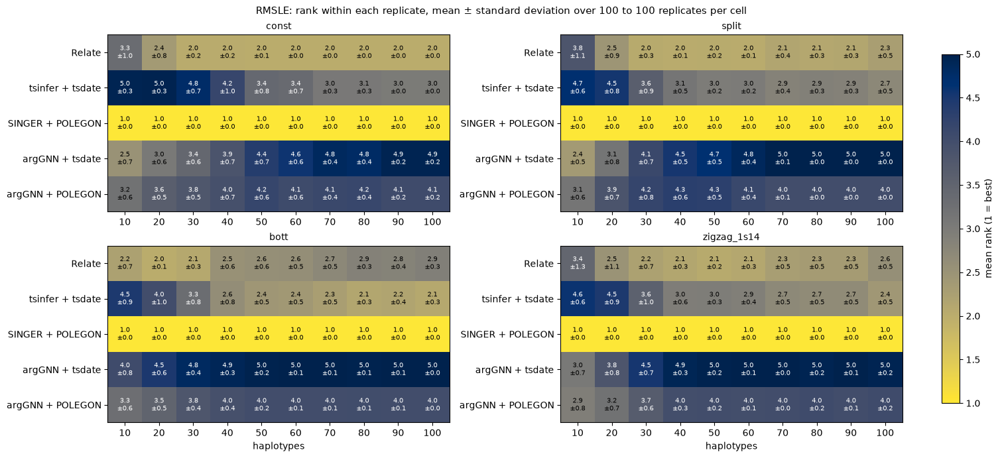

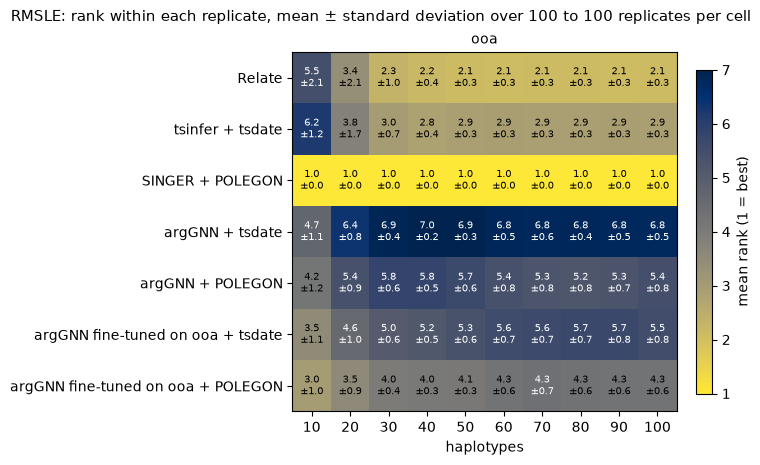

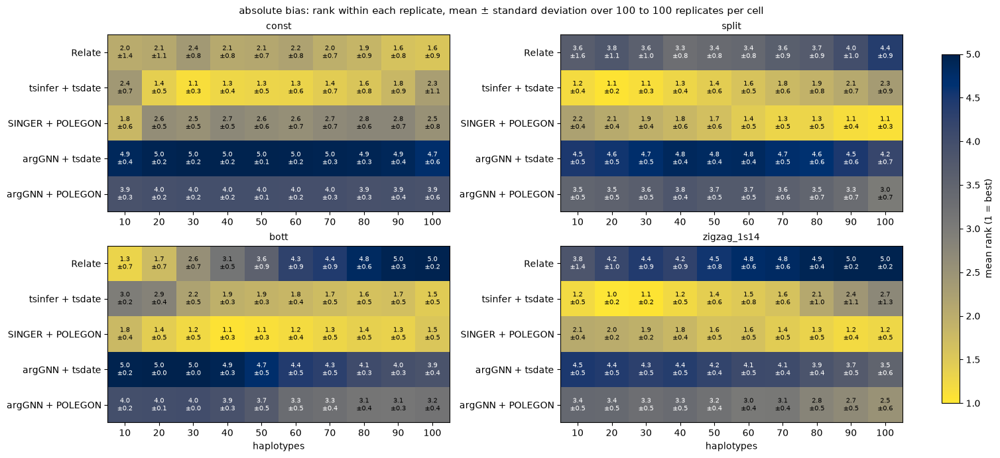

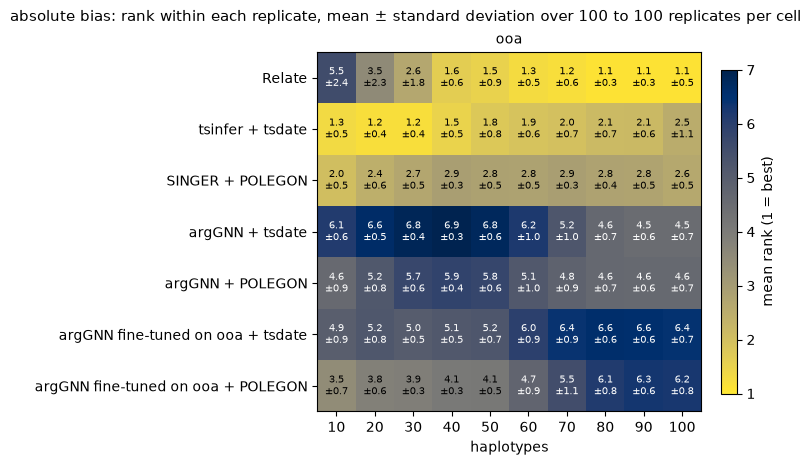

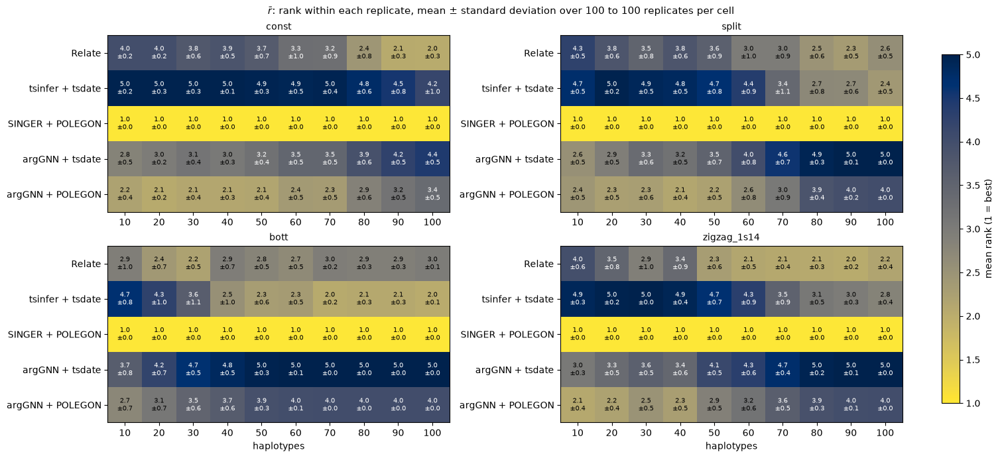

...

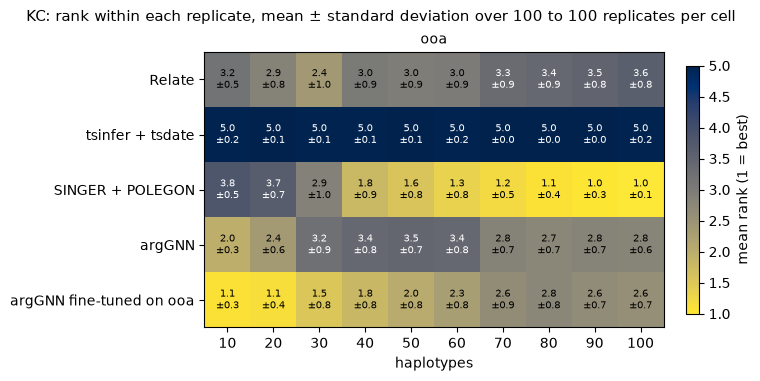

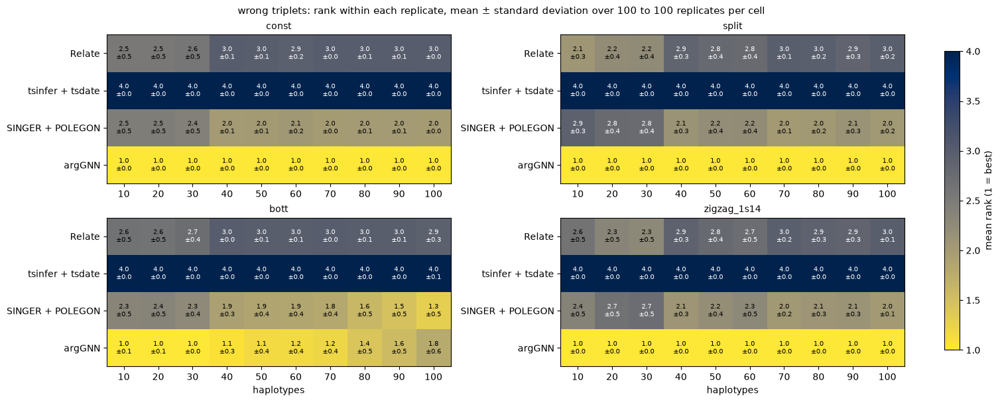

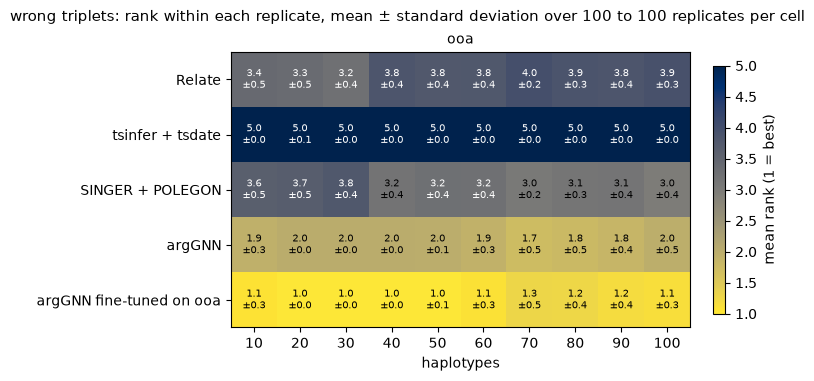

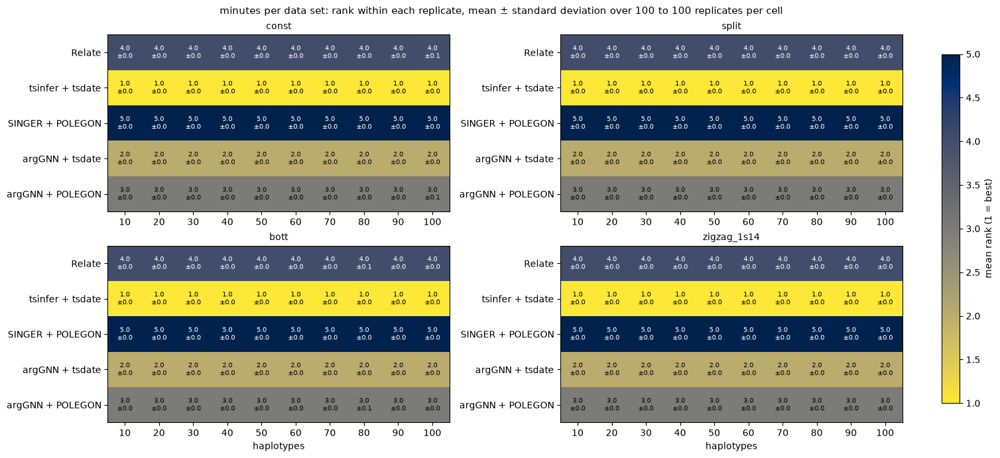

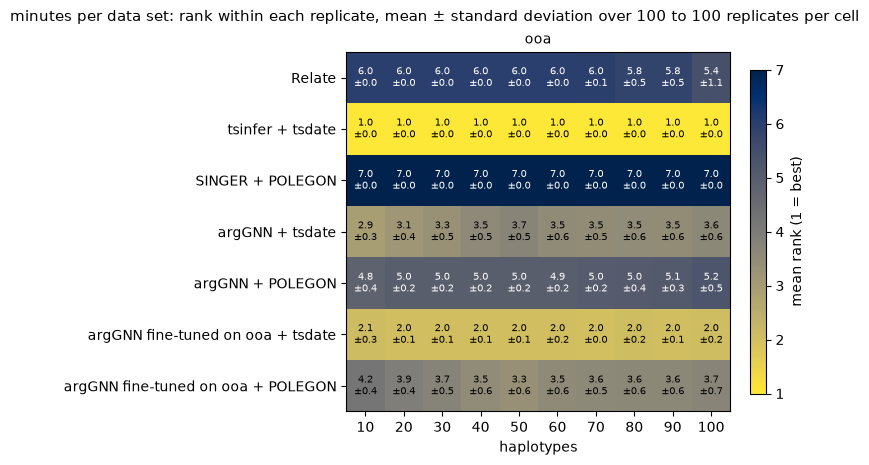

In [28]:
# The mean rank within each replicate of every metric of RANK_METRICS.
for metric in RANK_METRICS:
    plot_rank_heatmaps(metric)